# CV & DIP Labs — Combined Notebook

All lab experiments merged into one notebook. **Every code cell starts with a comment** like `# [Lab 5 | cell 7] ...` that tells you what it does and where it came from in the original lab file.

## Table of Contents (quick finder)
| Task you need | Go to |
|---|---|
| Read image, shape, resize, BGR→RGB, grayscale, RGBA | **Lab 1** |
| Show R / G / B channels separately | **Lab 1** |
| Histogram (gray, R, G, B) | **Lab 1** |
| Count objects (connected components, 4/8 connectivity) | **Lab 2** |
| Distance between pixels (Euclidean, D4, D8) | **Lab 2** |
| RGB → CMY, show C/M/Y channels | **Lab 2** |
| Histogram equalization (gray + colour) | **Lab 3** |
| Fourier Transform (FFT), magnitude spectrum, DCT | **Lab 4** |
| Spatial filters: correlation, convolution, mean, Gaussian | **Lab 5** |
| Sharpening: Roberts, Prewitt, Sobel, Laplacian, Highboost | **Lab 5** |
| Frequency-domain filters (Ideal / Gaussian / Butterworth LPF & HPF) | **Lab 6** *(added — see note)* |
| Salt-and-pepper noise + median filter | **Lab 7** |
| Gaussian noise + Gaussian filter | **Lab 8** |
| Global & adaptive thresholding | **Lab 9** |

> **Note about Lab 6:** your zip contained labs 1,2,3,4,5,7,8,9 — there was no `lab-6`. Since you mentioned *Frequency Domain Filters*, I added a Lab 6 section for it. It is new code written by me, not from your files; delete it if you don't want it.

## 0. Setup (run this first)
Change the three image paths below to match where your images are (e.g. `/content/...` in Colab). Every lab section after this uses these variables.

In [ ]:
# [Setup] Common imports + image paths used by ALL labs
# pip install opencv-python numpy matplotlib scipy ipykernel
# python -c "import cv2, numpy, matplotlib, scipy, ipykernel; print('All installed')"
%pip install opencv-python
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

IMG_NATURAL   = "istockphoto-1403500817-612x612.jpg"   # used in Labs 1-4
IMG_SMALL     = "49c33180-6bce-11f1-a94c-73f00a91c697.jpg"                                                  # used in Labs 5, 6, 7
IMG_DOGKITTEN = "images.jpeg"                                             # used in Labs 8, 9

Note: you may need to restart the kernel to use updated packages.


---
# Lab 1 — Image Basics, Colour Channels, Grayscale, RGBA, Histogram

### 1.1 Import libraries & read image
Loads the image with OpenCV (it is read in **BGR** order) and prints the pixel array and its shape (height, width, channels).

In [21]:
# [Lab 1 | cell 0] Import cv2 and matplotlib
import cv2
import matplotlib.pyplot as plt

In [22]:
# [Lab 1 | cell 1] Read image into a NumPy array (BGR)
img = cv2.imread(IMG_NATURAL)
img

array([[[141, 169, 216],
        [142, 170, 217],
        [142, 170, 217],
        ...,
        [115, 112, 128],
        [115, 112, 128],
        [115, 112, 128]],

       [[141, 169, 216],
        [141, 169, 216],
        [142, 170, 217],
        ...,
        [116, 113, 129],
        [116, 113, 129],
        [116, 113, 129]],

       [[140, 168, 215],
        [141, 169, 216],
        [141, 169, 216],
        ...,
        [118, 114, 133],
        [118, 114, 133],
        [118, 114, 133]],

       ...,

       [[  0,  41,  29],
        [  0,  42,  31],
        [  0,  39,  31],
        ...,
        [ 16,  93,  79],
        [  0,  12,  18],
        [ 27,  31,  59]],

       [[ 11,  42,  33],
        [  2,  25,  20],
        [  0,  19,  13],
        ...,
        [  4,  73,  62],
        [  0,   3,   6],
        [ 16,  34,  45]],

       [[ 30,  50,  45],
        [  4,  19,  15],
        [  0,   7,   4],
        ...,
        [ 24,  75,  77],
        [  0,  17,  22],
        [ 49,  74,  78]]

In [23]:
# [Lab 1 | cell 2] Print image shape (H, W, channels)
img.shape

(408, 612, 3)

### 1.2 Resize image & BGR → RGB conversion
Resize to 5×5 pixels to see raw values; convert BGR→RGB so matplotlib shows correct colours. Cell 5 shows the *wrong colours* (BGR shown directly) on purpose, cell 6 shows the correct one.

In [24]:
# [Lab 1 | cell 3] Resize image to 5x5
resized_img = cv2.resize(img, (5,5))
resized_img

array([[[109, 106, 134],
        [143, 203, 255],
        [167, 177, 215],
        [119, 116, 148],
        [140, 181, 254]],

       [[ 10,  72,  97],
        [ 93, 164, 243],
        [121, 157, 232],
        [120, 132, 198],
        [111, 117, 164]],

       [[ 22,  46,  62],
        [ 15,  87, 114],
        [144, 150, 225],
        [132, 114, 145],
        [113,  93, 105]],

       [[ 20,  95,  88],
        [ 10,  36,  48],
        [ 70,  99, 197],
        [  1,  41,  43],
        [ 51,  76,  78]],

       [[  1,  85,  73],
        [ 40,  87,  75],
        [  9,  14,  22],
        [ 18,  29,  23],
        [ 27,   2,  69]]], dtype=uint8)

In [25]:
# [Lab 1 | cell 4] Convert resized image BGR -> RGB
resized_img_rgb = cv2.cvtColor(resized_img, cv2.COLOR_BGR2RGB)
resized_img_rgb

array([[[134, 106, 109],
        [255, 203, 143],
        [215, 177, 167],
        [148, 116, 119],
        [254, 181, 140]],

       [[ 97,  72,  10],
        [243, 164,  93],
        [232, 157, 121],
        [198, 132, 120],
        [164, 117, 111]],

       [[ 62,  46,  22],
        [114,  87,  15],
        [225, 150, 144],
        [145, 114, 132],
        [105,  93, 113]],

       [[ 88,  95,  20],
        [ 48,  36,  10],
        [197,  99,  70],
        [ 43,  41,   1],
        [ 78,  76,  51]],

       [[ 73,  85,   1],
        [ 75,  87,  40],
        [ 22,  14,   9],
        [ 23,  29,  18],
        [ 69,   2,  27]]], dtype=uint8)

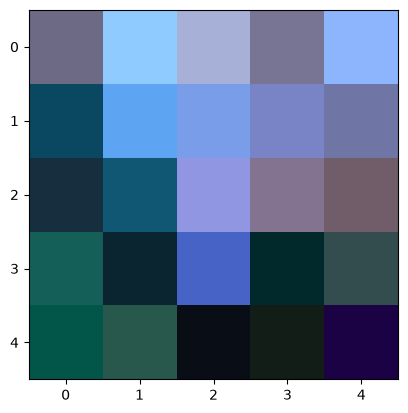

In [26]:
# [Lab 1 | cell 5] Display resized image (BGR, colours look wrong)
plt.imshow(resized_img)

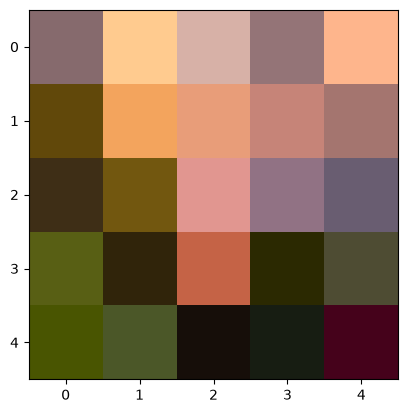

In [27]:
# [Lab 1 | cell 6] Display resized image (RGB, correct colours)
plt.imshow(resized_img_rgb)

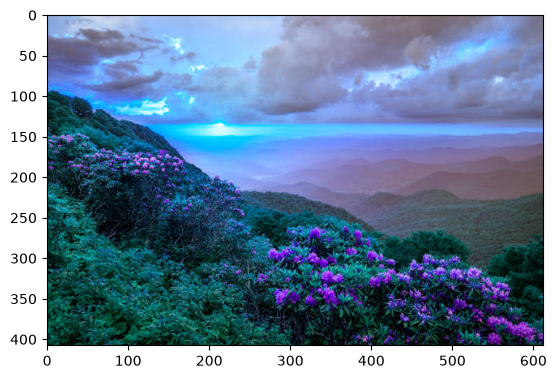

In [28]:
# [Lab 1 | cell 7] Display full image (BGR, colours look wrong)
plt.imshow(img)

In [29]:
# [Lab 1 | cell 8] Convert full image BGR -> RGB and print shape
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_rgb.shape

(408, 612, 3)

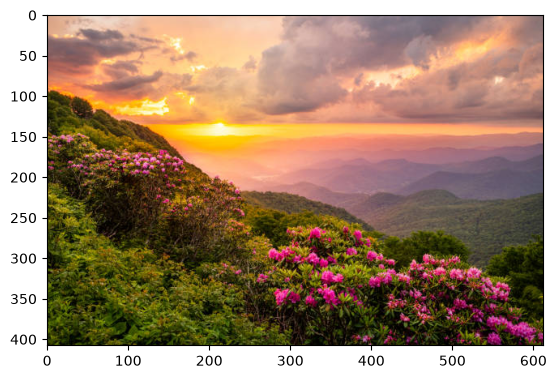

In [30]:
# [Lab 1 | cell 9] Display full image in correct RGB
plt.imshow(img_rgb)

### 1.3 Show individual colour channels (Red / Blue / Green only)
Keeps one channel and sets the other two to 0. Cells 10-11 are the BGR version (shows blue-ish because index order is BGR); cells 12-15 are the correct RGB version.

In [31]:
# [Lab 1 | cell 10] Red-channel image from BGR image (index 1,2 zeroed)
red_channel = img.copy()

# Set Blue (index 0) and Green (index 1) channels to 0
red_channel[:, :, 1] = 0
red_channel[:, :, 2] = 0

red_channel

array([[[141,   0,   0],
        [142,   0,   0],
        [142,   0,   0],
        ...,
        [115,   0,   0],
        [115,   0,   0],
        [115,   0,   0]],

       [[141,   0,   0],
        [141,   0,   0],
        [142,   0,   0],
        ...,
        [116,   0,   0],
        [116,   0,   0],
        [116,   0,   0]],

       [[140,   0,   0],
        [141,   0,   0],
        [141,   0,   0],
        ...,
        [118,   0,   0],
        [118,   0,   0],
        [118,   0,   0]],

       ...,

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [ 16,   0,   0],
        [  0,   0,   0],
        [ 27,   0,   0]],

       [[ 11,   0,   0],
        [  2,   0,   0],
        [  0,   0,   0],
        ...,
        [  4,   0,   0],
        [  0,   0,   0],
        [ 16,   0,   0]],

       [[ 30,   0,   0],
        [  4,   0,   0],
        [  0,   0,   0],
        ...,
        [ 24,   0,   0],
        [  0,   0,   0],
        [ 49,   0,   0]]

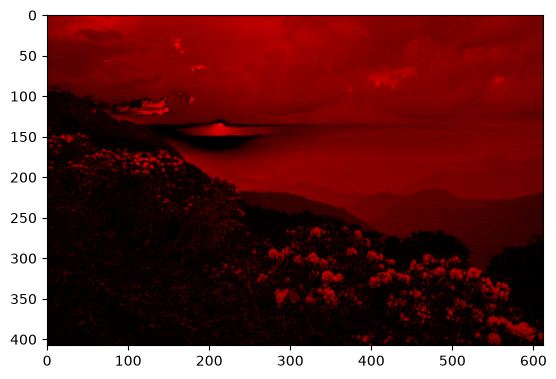

In [32]:
# [Lab 1 | cell 11] Display it
# Display the image
plt.imshow(red_channel)

In [33]:
# [Lab 1 | cell 12] Red channel only (RGB image)
# Make a copy to preserve the original image

red_channel = img_rgb.copy()

# Set Blue (index 0) and Green (index 1) channels to 0
red_channel[:, :, 1] = 0
red_channel[:, :, 2] = 0

red_channel

array([[[216,   0,   0],
        [217,   0,   0],
        [217,   0,   0],
        ...,
        [128,   0,   0],
        [128,   0,   0],
        [128,   0,   0]],

       [[216,   0,   0],
        [216,   0,   0],
        [217,   0,   0],
        ...,
        [129,   0,   0],
        [129,   0,   0],
        [129,   0,   0]],

       [[215,   0,   0],
        [216,   0,   0],
        [216,   0,   0],
        ...,
        [133,   0,   0],
        [133,   0,   0],
        [133,   0,   0]],

       ...,

       [[ 29,   0,   0],
        [ 31,   0,   0],
        [ 31,   0,   0],
        ...,
        [ 79,   0,   0],
        [ 18,   0,   0],
        [ 59,   0,   0]],

       [[ 33,   0,   0],
        [ 20,   0,   0],
        [ 13,   0,   0],
        ...,
        [ 62,   0,   0],
        [  6,   0,   0],
        [ 45,   0,   0]],

       [[ 45,   0,   0],
        [ 15,   0,   0],
        [  4,   0,   0],
        ...,
        [ 77,   0,   0],
        [ 22,   0,   0],
        [ 78,   0,   0]]

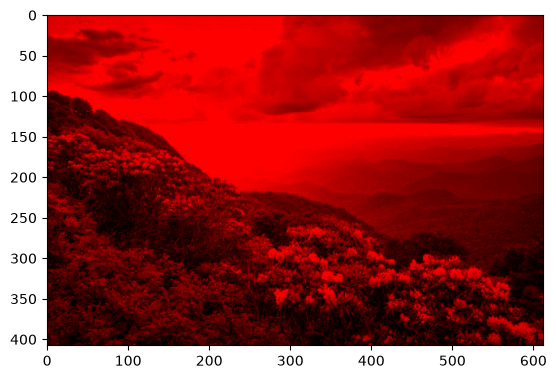

In [34]:
# [Lab 1 | cell 13] Display red channel
# Display the image
plt.imshow(red_channel)

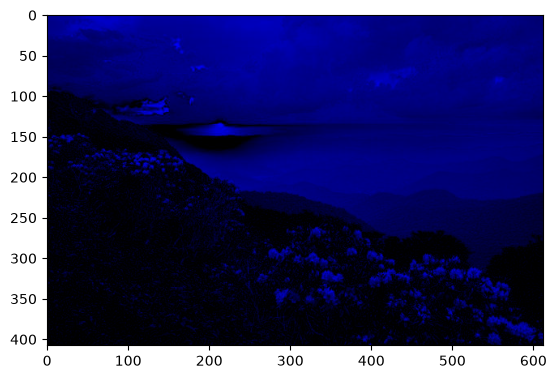

In [35]:
# [Lab 1 | cell 14] Blue channel only (RGB image) + display
# Make a copy to preserve the original image

blue_channel = img_rgb.copy()

# Set Blue (index 0) and Green (index 1) channels to 0
blue_channel[:, :, 0] = 0
blue_channel[:, :, 1] = 0

# Display the image
plt.imshow(blue_channel)

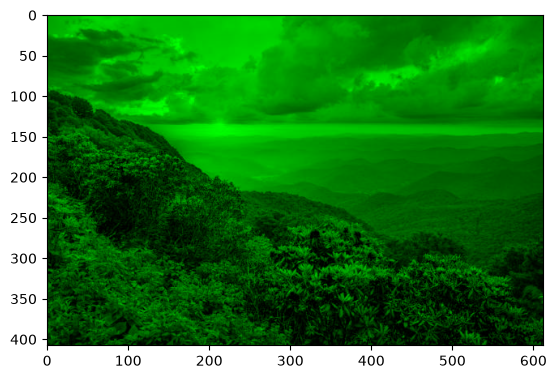

In [36]:
# [Lab 1 | cell 15] Green channel only (RGB image) + display
# Make a copy to preserve the original image

green_channel = img_rgb.copy()

# Set Blue (index 0) and Green (index 1) channels to 0
green_channel[:, :, 0] = 0
green_channel[:, :, 2] = 0

# Display the image
plt.imshow(green_channel)

### 1.4 Convert to Grayscale
RGB/BGR → single-channel grayscale image.

In [37]:
# [Lab 1 | cell 16] Convert to grayscale
# Convert RGB to grayscale
gray_image = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray_image

array([[180, 181, 181, ..., 117, 117, 117],
       [180, 180, 181, ..., 118, 118, 118],
       [179, 180, 180, ..., 120, 120, 120],
       ...,
       [ 33,  34,  32, ...,  80,  12,  39],
       [ 36,  21,  15, ...,  62,   4,  35],
       [ 46,  16,   5, ...,  70,  17,  72]], shape=(408, 612), dtype=uint8)

In [38]:
# [Lab 1 | cell 17] Grayscale shape (H, W)
gray_image.shape

(408, 612)

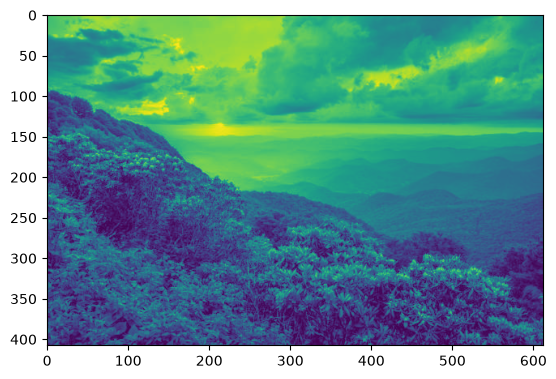

In [39]:
# [Lab 1 | cell 18] Display grayscale image
plt.imshow(gray_image)

### 1.5 Convert to RGBA & change transparency
Adds an alpha (transparency) channel; setting alpha = 100 makes the image semi-transparent.

In [40]:
# [Lab 1 | cell 19] Convert to RGBA
rgba_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGBA)
rgba_img

array([[[216, 169, 141, 255],
        [217, 170, 142, 255],
        [217, 170, 142, 255],
        ...,
        [128, 112, 115, 255],
        [128, 112, 115, 255],
        [128, 112, 115, 255]],

       [[216, 169, 141, 255],
        [216, 169, 141, 255],
        [217, 170, 142, 255],
        ...,
        [129, 113, 116, 255],
        [129, 113, 116, 255],
        [129, 113, 116, 255]],

       [[215, 168, 140, 255],
        [216, 169, 141, 255],
        [216, 169, 141, 255],
        ...,
        [133, 114, 118, 255],
        [133, 114, 118, 255],
        [133, 114, 118, 255]],

       ...,

       [[ 29,  41,   0, 255],
        [ 31,  42,   0, 255],
        [ 31,  39,   0, 255],
        ...,
        [ 79,  93,  16, 255],
        [ 18,  12,   0, 255],
        [ 59,  31,  27, 255]],

       [[ 33,  42,  11, 255],
        [ 20,  25,   2, 255],
        [ 13,  19,   0, 255],
        ...,
        [ 62,  73,   4, 255],
        [  6,   3,   0, 255],
        [ 45,  34,  16, 255]],

       [[ 45

In [41]:
# [Lab 1 | cell 20] RGBA shape (H, W, 4)
rgba_img.shape

(408, 612, 4)

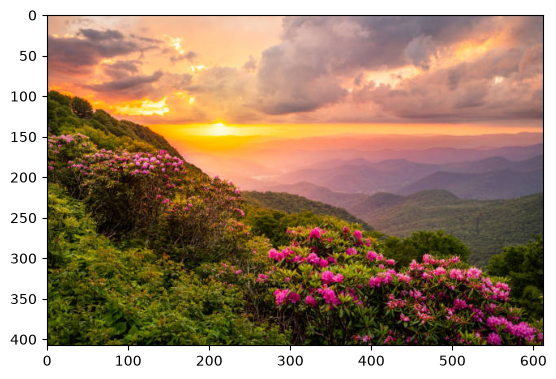

In [42]:
# [Lab 1 | cell 21] Display RGBA image
plt.imshow(rgba_img)

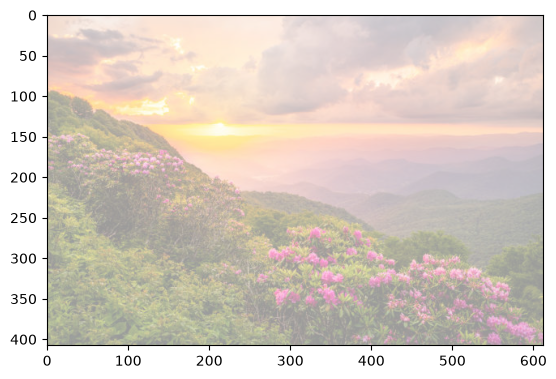

In [43]:
# [Lab 1 | cell 22] Set alpha channel = 100 and display
rgba_img1 = rgba_img.copy()
rgba_img1[:, :, 3] = 100
plt.imshow(rgba_img1)

### 1.6 Histogram (Grayscale, Red, Blue, Green)
A histogram shows how many pixels have each intensity value (0-255).

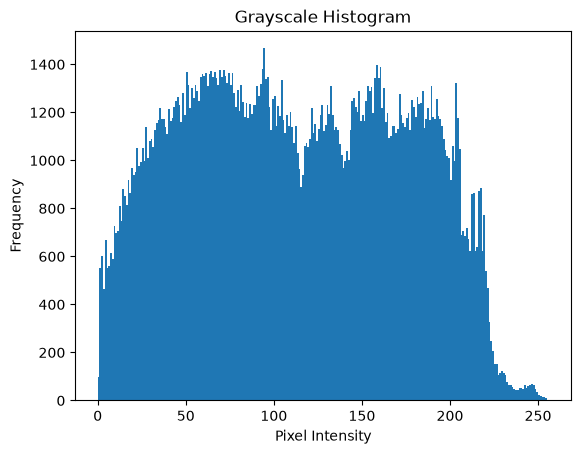

In [44]:
# [Lab 1 | cell 24] Histogram of grayscale image
# Plot the histogram of gray scale image
plt.hist(gray_image.ravel(), bins=256, range=[0, 256])

plt.title("Grayscale Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

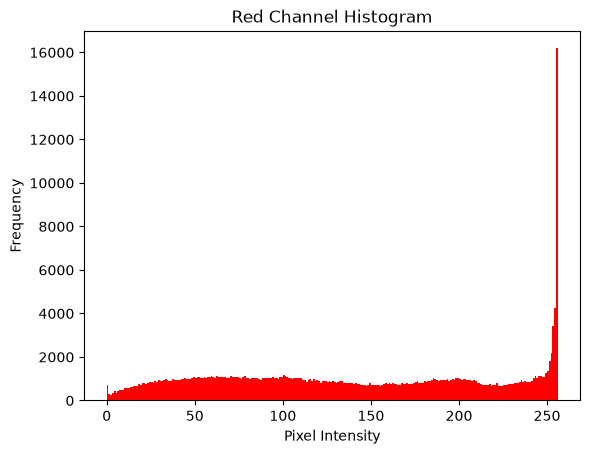

In [45]:
# [Lab 1 | cell 25] Histogram of Red channel
# Plot the histogram of Red channel image
plt.hist(img_rgb[:,:,0].ravel(), bins=256, range=[0, 256],color='red')

plt.title("Red Channel Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

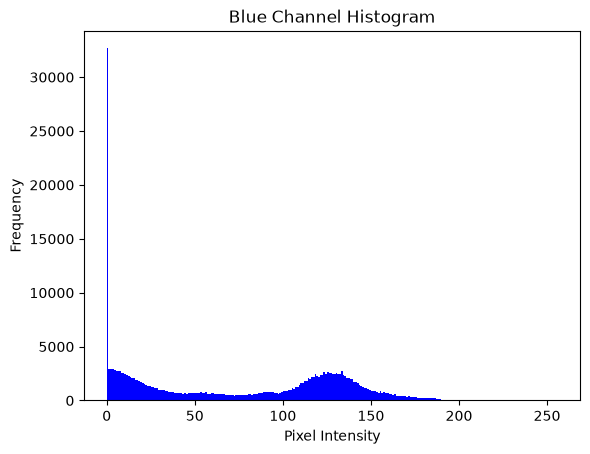

In [46]:
# [Lab 1 | cell 26] Histogram of Blue channel
# Plot the histogram of Blue channel image
plt.hist(img_rgb[:,:,2].ravel(), bins=256, range=[0, 256],color='blue')

plt.title("Blue Channel Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

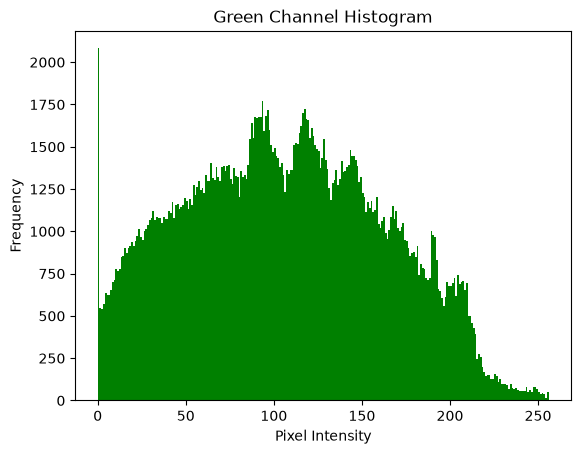

In [47]:
# [Lab 1 | cell 27] Histogram of Green channel
# Plot the histogram of Green channel image
plt.hist(img_rgb[:,:,1].ravel(), bins=256, range=[0, 256], color='green')

plt.title("Green Channel Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

---
# Lab 2 — Connected Components (Counting Objects), Pixel Distances, RGB → CMY

### 2.1 Count objects in a binary image — 4-connectivity
Uses `ndimage.label` with a 4-neighbour structure (up/down/left/right). Prints number of objects and the labelled matrix.

In [48]:
# [Lab 2 | cell 0] Import numpy + scipy ndimage
import numpy as np
from scipy import ndimage

In [49]:
# [Lab 2 | cell 2] Create binary image grid
imageGrid = np.array([
    [0, 0, 0, 1, 0, 0],
    [0, 1, 1, 0, 0, 0],
    [0, 1, 1, 0, 0, 0],
    [1, 0, 0, 0, 1, 0],
    [0, 0, 0, 1, 1, 0],
    [0, 0, 0, 0, 0, 0]
])

In [50]:
# [Lab 2 | cell 3] Define 4-connectivity structure
four_connectivity_structure = [
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
]

In [51]:
# [Lab 2 | cell 4] Label connected components
#Label the connected Components
labeled_image, number_of_objects = ndimage.label(imageGrid,
                                                 structure=four_connectivity_structure)

In [52]:
# [Lab 2 | cell 5] Print object count + labelled matrix
# 4. Output the results
print(f"Number of distinct objects found: {number_of_objects}")
print("\nLabeled Grid Matrix (Each object gets a unique ID):")
print(labeled_image)

Number of distinct objects found: 4

Labeled Grid Matrix (Each object gets a unique ID):
[[0 0 0 1 0 0]
 [0 2 2 0 0 0]
 [0 2 2 0 0 0]
 [3 0 0 0 4 0]
 [0 0 0 4 4 0]
 [0 0 0 0 0 0]]


### 2.2 Count objects — 8-connectivity
Same as above but diagonal neighbours also count as connected.

In [53]:
# [Lab 2 | cell 6] Define 8-connectivity structure
eight_connectivity_structure = [
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1]
]

In [54]:
# [Lab 2 | cell 7] Label connected components (8-conn)
#Label the connected Components
labeled_image, number_of_objects = ndimage.label(imageGrid,
                                                 structure=eight_connectivity_structure)

In [55]:
# [Lab 2 | cell 8] Print object count + labelled matrix
# 4. Output the results
print(f"Number of distinct objects found: {number_of_objects}")
print("\nLabeled Grid Matrix (Each object gets a unique ID):")
print(labeled_image)

Number of distinct objects found: 2

Labeled Grid Matrix (Each object gets a unique ID):
[[0 0 0 1 0 0]
 [0 1 1 0 0 0]
 [0 1 1 0 0 0]
 [1 0 0 0 2 0]
 [0 0 0 2 2 0]
 [0 0 0 0 0 0]]


### 2.3 Count objects in a grayscale image (using target values)
Converts grayscale to binary by keeping only chosen pixel values (50, 100, 150), then counts objects. **Needs the 8-connectivity structure from 2.2.**

In [56]:
# [Lab 2 | cell 10] Create example grayscale image
# Example grayscale image
image = np.array([
    [10,   0, 100, 100, 20,   3],
    [60,   100, 100, 34,   12,   50],
    [45,   209,  144,   255,   50, 50],
    [200, 200, 123,  23,   34,   23],
    [200, 10,   24,  100, 100, 20]
])

In [57]:
# [Lab 2 | cell 11] Convert to binary using target pixel values
target_values = [50, 100, 150]

binary_image = np.isin(image, target_values).astype(np.uint8)
binary_image

array([[0, 0, 1, 1, 0, 0],
       [0, 1, 1, 0, 0, 1],
       [0, 0, 0, 0, 1, 1],
       [0, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 1, 0]], dtype=uint8)

In [58]:
# [Lab 2 | cell 12] Label and count objects
#Label the connected Components
labeled_image, number_of_objects = ndimage.label(binary_image,
                                                 structure=eight_connectivity_structure)
print('Number of Objects =',number_of_objects)
print()
print(labeled_image)

Number of Objects = 3

[[0 0 1 1 0 0]
 [0 1 1 0 0 2]
 [0 0 0 0 2 2]
 [0 0 0 0 0 0]
 [0 0 0 3 3 0]]


### 2.4 Distance between two pixels (Euclidean, D4, D8)
Finds coordinates of pixels `p` and `q` in a grid and calculates the three standard distance measures.

In [59]:
# [Lab 2 | cell 14] Grid containing pixels p and q
image1 = [
    ['p',0,0],
    [0,0,0],
    [0,0,'q']
]

In [60]:
# [Lab 2 | cell 15] Find coordinates of p and q
#Let's find the cordinates of 'p' and 'q'
for i in range(len(image1)):
  if 'p' in image1[i]:
    p_cordinates = (i,image1[i].index('p'))
  if 'q' in image1[i]:
    q_cordinates = (i,image1[i].index('q'))


In [61]:
# [Lab 2 | cell 16] Print coordinates
print('Cordinates of P =',p_cordinates)
print('Cordinates of Q =',q_cordinates)

Cordinates of P = (0, 0)
Cordinates of Q = (2, 2)


In [62]:
# [Lab 2 | cell 17] Euclidean distance
# Eucledian Distance
eucledian_distance = np.sqrt((p_cordinates[0]-q_cordinates[0])**2 + (p_cordinates[1]-q_cordinates[1])**2)
print('Eucledian Distance =',eucledian_distance )

Eucledian Distance = 2.8284271247461903


In [63]:
# [Lab 2 | cell 18] City-block distance (D4)
# City Block Distance (D4)
d4_distance = abs(p_cordinates[0]-q_cordinates[0]) + abs(p_cordinates[1]-q_cordinates[1])
print('City Block Distance =',d4_distance)

City Block Distance = 4


In [64]:
# [Lab 2 | cell 19] Chessboard distance (D8)
# Chessboard Distance (D8)
d8_distance = max(abs(p_cordinates[0]-q_cordinates[0]),abs(p_cordinates[1]-q_cordinates[1]))
print('City Block Distance =',d8_distance)

City Block Distance = 2


### 2.5 Convert RGB image → CMY and show channels
CMY = 255 − RGB. Then shows the R, G, B and the C, M, Y components as coloured images.

In [65]:
# [Lab 2 | cell 21] Imports
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [66]:
# [Lab 2 | cell 22] Read image
# Read RGB image
image = cv2.imread(IMG_NATURAL)

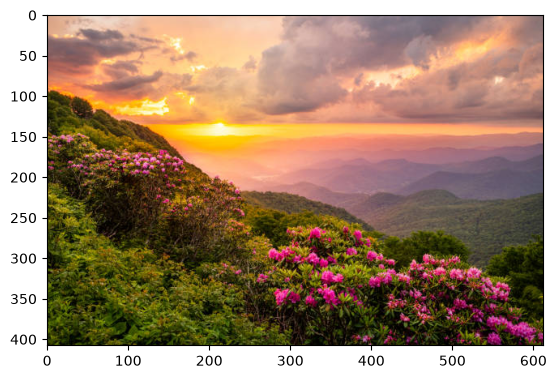

In [67]:
# [Lab 2 | cell 23] BGR -> RGB and display
# OpenCV reads images as BGR, so convert to RGB
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(rgb)
plt.show()

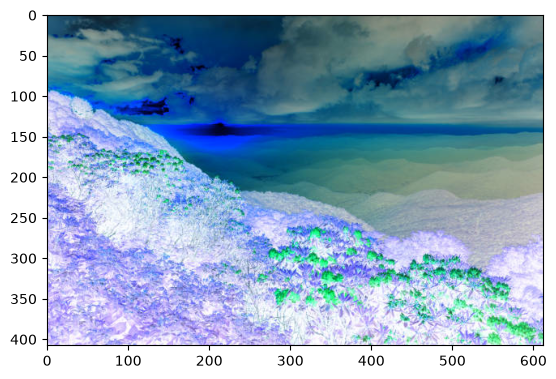

In [68]:
# [Lab 2 | cell 24] RGB -> CMY (255 - rgb) and display
cmy = 255 - rgb
plt.imshow(cmy)
plt.show()

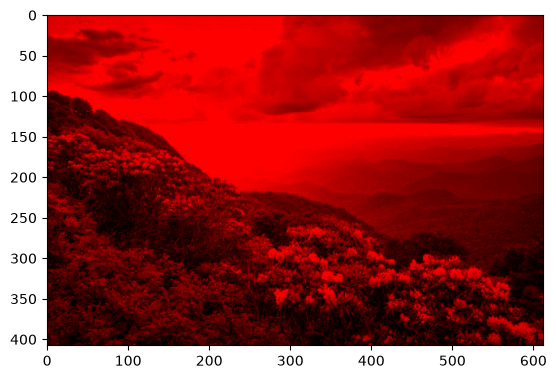

In [69]:
# [Lab 2 | cell 25] Show Red component
red = rgb.copy()
red[:,:,1] = 0
red[:,:,2] = 0
plt.imshow(red)
plt.show()

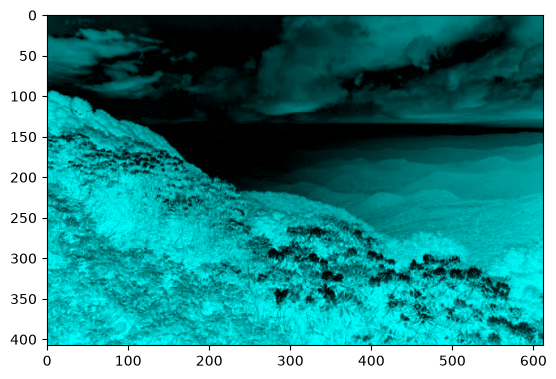

In [70]:
# [Lab 2 | cell 26] Show Cyan component
cyan = cmy.copy()
C = cmy[:, :, 0]
cyan[:, :, 0] = 0
cyan[:, :, 1] = C
cyan[:, :, 2] = C
plt.imshow(cyan)
plt.show()

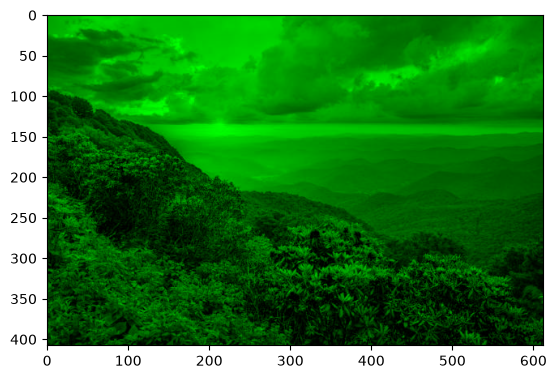

In [71]:
# [Lab 2 | cell 27] Show Green component
green = rgb.copy()
green[:,:,0] = 0
green[:,:,2] = 0
plt.imshow(green)
plt.show()

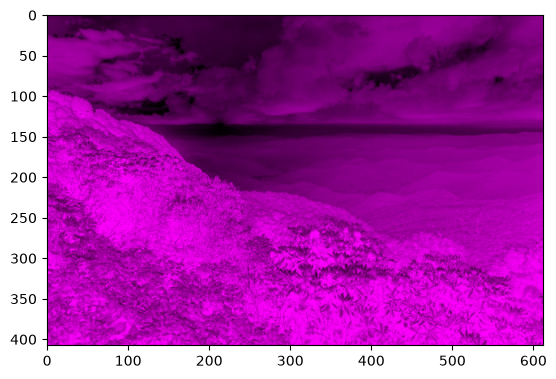

In [72]:
# [Lab 2 | cell 28] Show Magenta component
magenta = cmy.copy()
M = cmy[:, :, 1]
magenta[:, :, 1] = 0
magenta[:, :, 0] = M
magenta[:, :, 2] = M

plt.imshow(magenta)
plt.show()

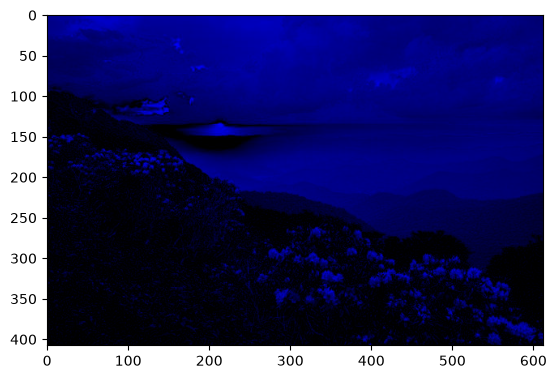

In [73]:
# [Lab 2 | cell 29] Show Blue component
blue = rgb.copy()
blue[:,:,0] = 0
blue[:,:,1] = 0
plt.imshow(blue)
plt.show()

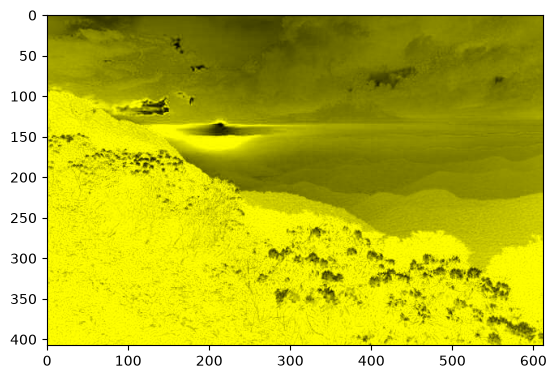

In [74]:
# [Lab 2 | cell 30] Show Yellow component
yellow = cmy.copy()
Y = cmy[:, :, 2]
yellow[:, :, 2] = 0
yellow[:, :, 0] = Y
yellow[:, :, 1] = Y

plt.imshow(yellow)
plt.show()

---
# Lab 3 — Histogram Equalization (Gray and Colour)

### 3.1 Read image and show overall histogram
`ravel()` flattens the image to 1-D so a histogram can be plotted.

In [75]:
# [Lab 3 | cell 0] Imports
import cv2
import matplotlib.pyplot as plt

In [76]:
# [Lab 3 | cell 1] Read image + shape
image = cv2.imread(IMG_NATURAL)
image.shape

(408, 612, 3)

In [77]:
# [Lab 3 | cell 2] Print pixel array
image

array([[[141, 169, 216],
        [142, 170, 217],
        [142, 170, 217],
        ...,
        [115, 112, 128],
        [115, 112, 128],
        [115, 112, 128]],

       [[141, 169, 216],
        [141, 169, 216],
        [142, 170, 217],
        ...,
        [116, 113, 129],
        [116, 113, 129],
        [116, 113, 129]],

       [[140, 168, 215],
        [141, 169, 216],
        [141, 169, 216],
        ...,
        [118, 114, 133],
        [118, 114, 133],
        [118, 114, 133]],

       ...,

       [[  0,  41,  29],
        [  0,  42,  31],
        [  0,  39,  31],
        ...,
        [ 16,  93,  79],
        [  0,  12,  18],
        [ 27,  31,  59]],

       [[ 11,  42,  33],
        [  2,  25,  20],
        [  0,  19,  13],
        ...,
        [  4,  73,  62],
        [  0,   3,   6],
        [ 16,  34,  45]],

       [[ 30,  50,  45],
        [  4,  19,  15],
        [  0,   7,   4],
        ...,
        [ 24,  75,  77],
        [  0,  17,  22],
        [ 49,  74,  78]]

In [78]:
# [Lab 3 | cell 3] Flatten image
image.ravel()

array([141, 169, 216, ...,  49,  74,  78], shape=(749088,), dtype=uint8)

In [79]:
# [Lab 3 | cell 4] Flattened size
image.ravel().shape

(749088,)

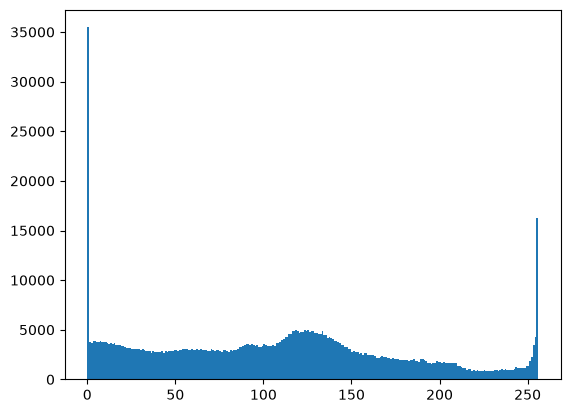

In [80]:
# [Lab 3 | cell 5] Histogram of all pixel values
plt.hist(image.ravel(), bins=256, range=[0, 256])
plt.show()

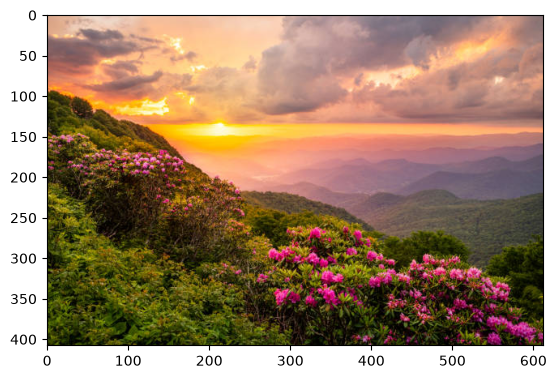

In [81]:
# [Lab 3 | cell 6] BGR -> RGB and display
img_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.show()

### 3.2 Grayscale conversion and display
Cell 7 uses default colormap, cell 8 uses `cmap='gray'` (correct grayscale look).

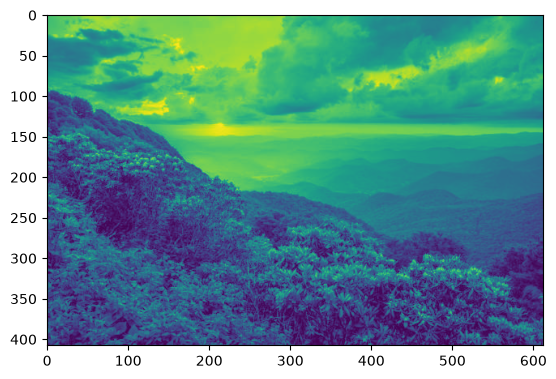

In [82]:
# [Lab 3 | cell 7] Convert to gray and display (default colormap)
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray)
plt.show()

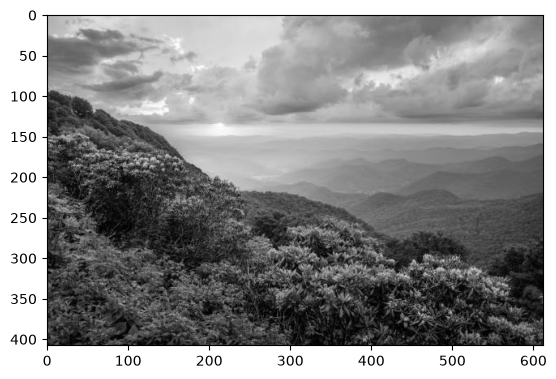

In [83]:
# [Lab 3 | cell 8] Display gray with cmap='gray'
plt.imshow(image_gray, cmap='gray')
plt.show()

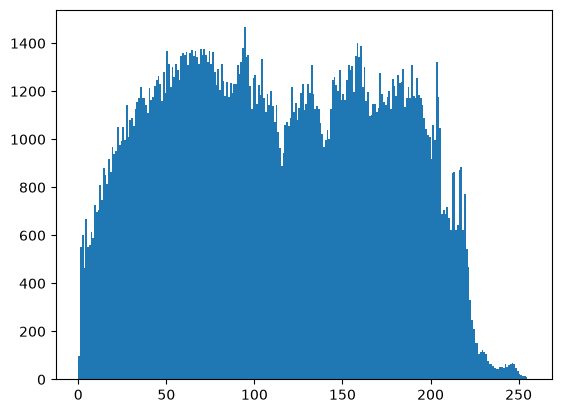

In [84]:
# [Lab 3 | cell 9] Histogram of gray image
plt.hist(image_gray.ravel(), bins=256, range=[0, 256])
plt.show()

### 3.3 Histogram Equalization of grayscale image
`cv2.equalizeHist` spreads intensities to improve contrast. Compare before/after histograms.

In [85]:
# [Lab 3 | cell 10] Apply histogram equalization
equilized_image_gray = cv2.equalizeHist(image_gray)
equilized_image_gray

array([[211, 213, 213, ..., 135, 135, 135],
       [211, 211, 213, ..., 137, 137, 137],
       [210, 211, 211, ..., 139, 139, 139],
       ...,
       [ 29,  30,  28, ...,  90,   8,  36],
       [ 32,  16,  10, ...,  66,   2,  31],
       [ 45,  11,   3, ...,  77,  12,  80]], shape=(408, 612), dtype=uint8)

In [86]:
# [Lab 3 | cell 11] Shape of equalized image
equilized_image_gray.shape

(408, 612)

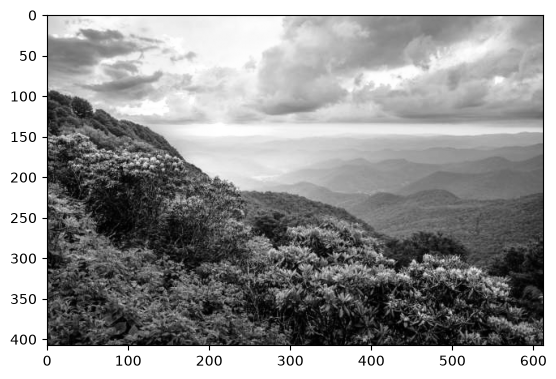

In [87]:
# [Lab 3 | cell 12] Display equalized image
plt.imshow(equilized_image_gray, cmap='gray')
plt.show()

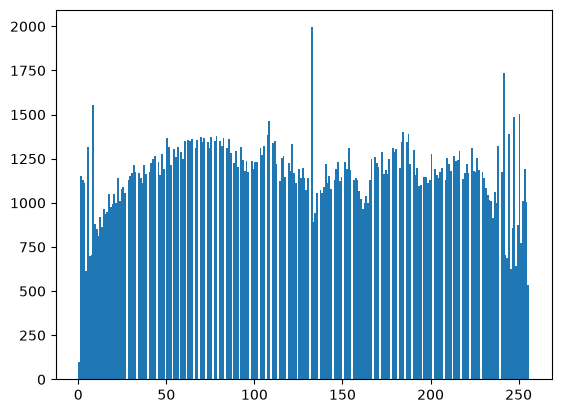

In [88]:
# [Lab 3 | cell 13] Histogram after equalization
plt.hist(equilized_image_gray.ravel(), bins=256, range=[0, 256])
plt.show()

### 3.4 Histograms of original R, G, B channels


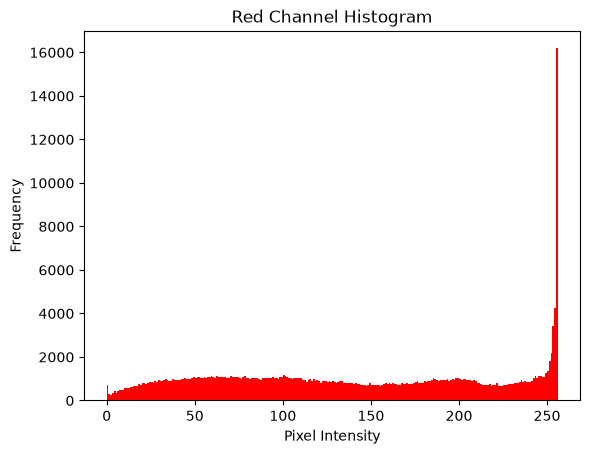

In [89]:
# [Lab 3 | cell 14] Red channel histogram
# Plot the histogram of Red channel image
plt.hist(img_rgb[:,:,0].ravel(), bins=256, range=[0, 256],color='red')

plt.title("Red Channel Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

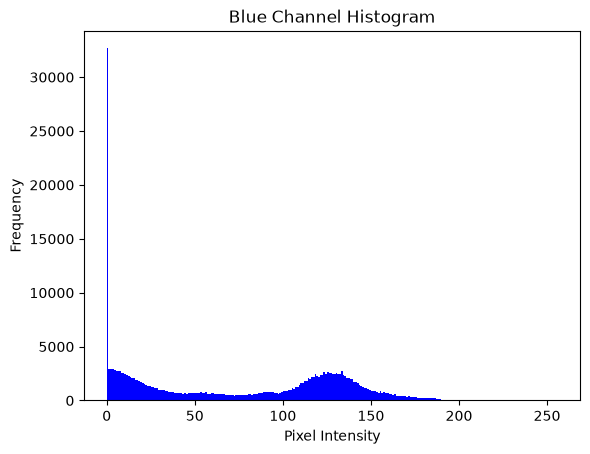

In [90]:
# [Lab 3 | cell 15] Blue channel histogram
# Plot the histogram of Blue channel image
plt.hist(img_rgb[:,:,2].ravel(), bins=256, range=[0, 256],color='blue')

plt.title("Blue Channel Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

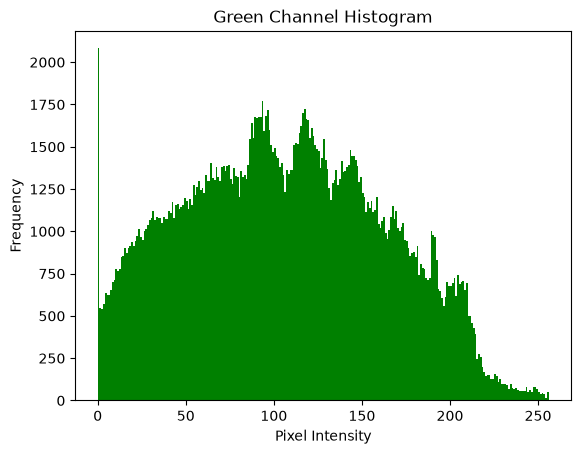

In [91]:
# [Lab 3 | cell 16] Green channel histogram
# Plot the histogram of Green channel image
plt.hist(img_rgb[:,:,1].ravel(), bins=256, range=[0, 256], color='green')

plt.title("Green Channel Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

### 3.5 Split channels
`cv2.split` separates the image into its R, G, B arrays.

In [92]:
# [Lab 3 | cell 17] Split into r, g, b
r,g,b= cv2.split(img_rgb)

In [93]:
# [Lab 3 | cell 18] Red intensities
#intensities of red channel
r

array([[216, 217, 217, ..., 128, 128, 128],
       [216, 216, 217, ..., 129, 129, 129],
       [215, 216, 216, ..., 133, 133, 133],
       ...,
       [ 29,  31,  31, ...,  79,  18,  59],
       [ 33,  20,  13, ...,  62,   6,  45],
       [ 45,  15,   4, ...,  77,  22,  78]], shape=(408, 612), dtype=uint8)

In [94]:
# [Lab 3 | cell 19] Red shape
r.shape

(408, 612)

In [95]:
# [Lab 3 | cell 20] Green intensities
#intensities of green channel
g

array([[169, 170, 170, ..., 112, 112, 112],
       [169, 169, 170, ..., 113, 113, 113],
       [168, 169, 169, ..., 114, 114, 114],
       ...,
       [ 41,  42,  39, ...,  93,  12,  31],
       [ 42,  25,  19, ...,  73,   3,  34],
       [ 50,  19,   7, ...,  75,  17,  74]], shape=(408, 612), dtype=uint8)

In [96]:
# [Lab 3 | cell 21] Green shape
g.shape

(408, 612)

In [97]:
# [Lab 3 | cell 22] Blue intensities
#intensities of blue channel
b

array([[141, 142, 142, ..., 115, 115, 115],
       [141, 141, 142, ..., 116, 116, 116],
       [140, 141, 141, ..., 118, 118, 118],
       ...,
       [  0,   0,   0, ...,  16,   0,  27],
       [ 11,   2,   0, ...,   4,   0,  16],
       [ 30,   4,   0, ...,  24,   0,  49]], shape=(408, 612), dtype=uint8)

### 3.6 Histogram Equalization of colour image (each channel)
Equalize R, G, B separately and merge back with `cv2.merge`.

In [98]:
# [Lab 3 | cell 23] Equalize each channel and merge
# Equalize each channel
r_eq = cv2.equalizeHist(r)
g_eq = cv2.equalizeHist(g)
b_eq = cv2.equalizeHist(b)

# Merge channels
equalized_rgb = cv2.merge([r_eq, g_eq, b_eq])

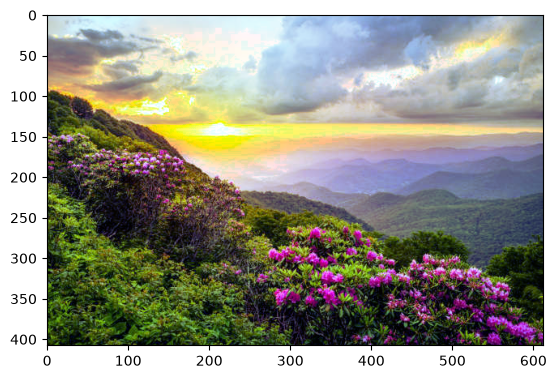

In [99]:
# [Lab 3 | cell 24] Display equalized colour image
plt.imshow(equalized_rgb)
plt.show()

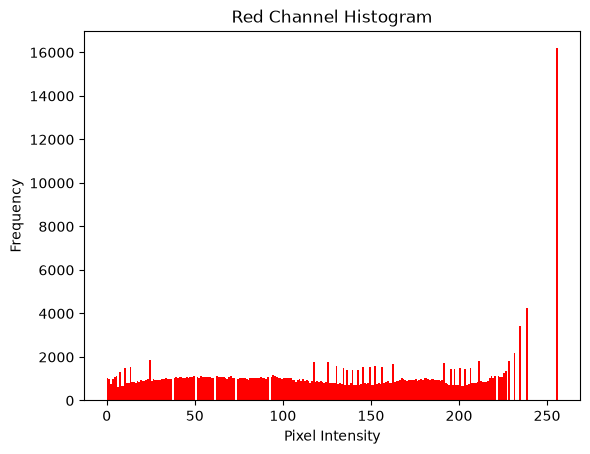

In [100]:
# [Lab 3 | cell 25] Equalized Red histogram
# Plot the histogram of Red channel image
plt.hist(equalized_rgb[:,:,0].ravel(), bins=256, range=[0, 256],color='red')

plt.title("Red Channel Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

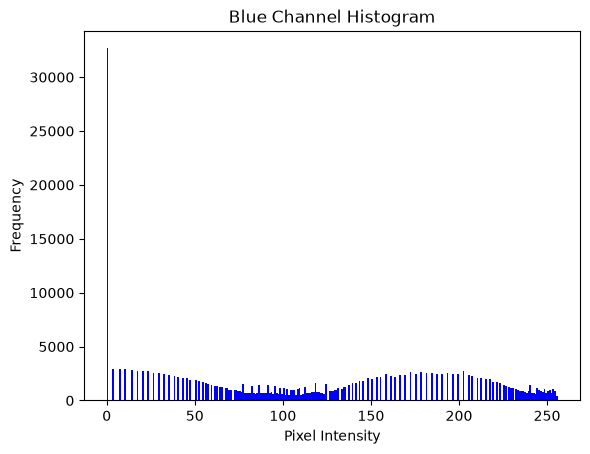

In [101]:
# [Lab 3 | cell 26] Equalized Blue histogram
# Plot the histogram of Blue channel image
plt.hist(equalized_rgb[:,:,2].ravel(), bins=256, range=[0, 256],color='blue')

plt.title("Blue Channel Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

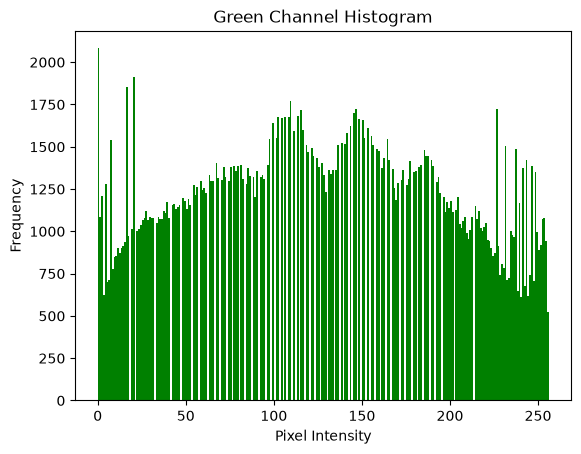

In [102]:
# [Lab 3 | cell 27] Equalized Green histogram
# Plot the histogram of Green channel image
plt.hist(equalized_rgb[:,:,1].ravel(), bins=256, range=[0, 256], color='green')

plt.title("Green Channel Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

---
# Lab 4 — Fourier Transform (FFT) and Discrete Cosine Transform (DCT)

### 4.1 Read image and convert to grayscale
Two ways to get a gray image: convert after reading, or read directly with flag `0`.

In [103]:
# [Lab 4 | cell 0] Imports
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [104]:
# [Lab 4 | cell 1] Read image
image = cv2.imread(IMG_NATURAL)

In [105]:
# [Lab 4 | cell 2] Shape
image.shape

(408, 612, 3)

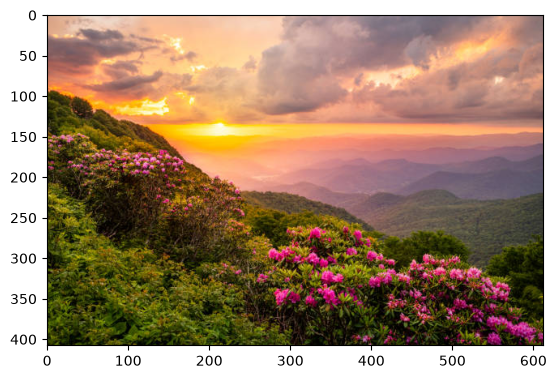

In [106]:
# [Lab 4 | cell 3] BGR -> RGB and display
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image_rgb)
plt.show()

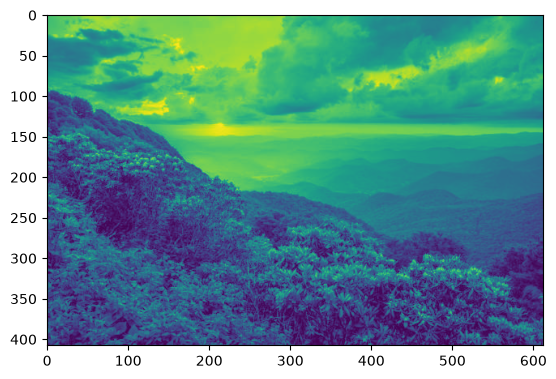

In [107]:
# [Lab 4 | cell 4] Convert to gray and display
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray)
plt.show()

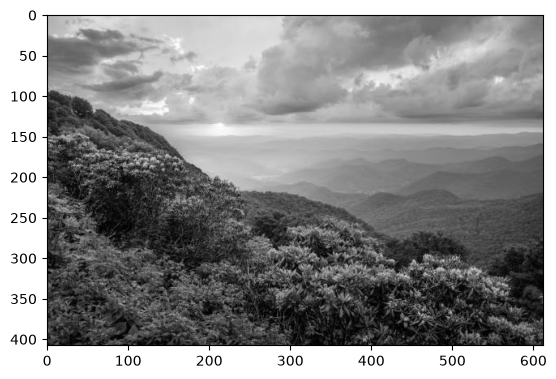

In [108]:
# [Lab 4 | cell 5] Display gray with cmap='gray'
plt.imshow(image_gray, cmap='gray')
plt.show()

In [109]:
# [Lab 4 | cell 6] Gray shape
image_gray.shape

(408, 612)

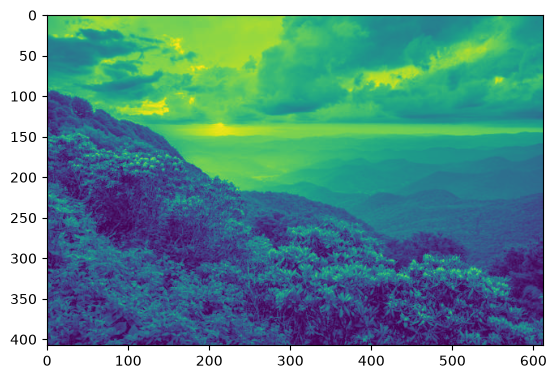

In [110]:
# [Lab 4 | cell 7] Read image directly as grayscale (flag 0)
image2 = cv2.imread(IMG_NATURAL,0)
plt.imshow(image2)
plt.show()

In [111]:
# [Lab 4 | cell 8] Shape
image2.shape

(408, 612)

### 4.2 Fourier Transform and magnitude spectrum
`fft2` gives complex frequency values. `fftshift` moves the zero-frequency (DC) component to the centre. Magnitude uses log scale so it is visible.

In [112]:
# [Lab 4 | cell 9] 2D FFT of gray image
# Fourier Transform
f = np.fft.fft2(image_gray)
f.shape

(408, 612)

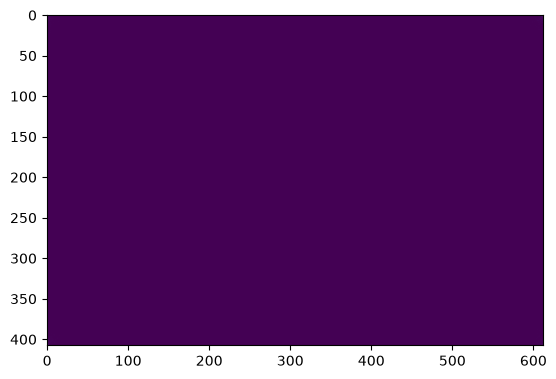

In [113]:
# [Lab 4 | cell 10] Display raw FFT (abs value; not very useful, magnitude spectrum below is better)
plt.imshow(np.abs(f))   # abs() added: newer matplotlib cannot plot complex numbers directly
plt.show()

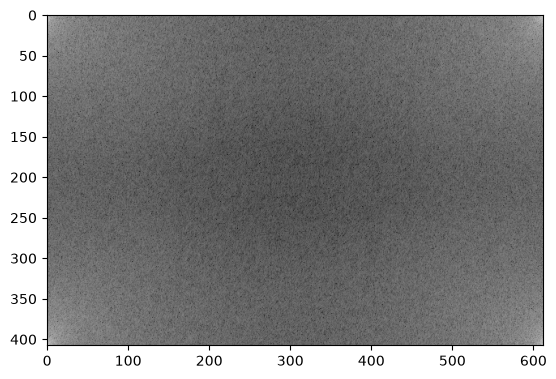

In [114]:
# [Lab 4 | cell 11] Magnitude spectrum (un-shifted)
# Magnitude spectrum
magnitude = 20 * np.log(np.abs(f) + 1)
plt.imshow(magnitude, cmap='gray')
plt.show()

In [115]:
# [Lab 4 | cell 12] Shift zero frequency to centre
# Shift zero frequency to center
fshift = np.fft.fftshift(f)
fshift

array([[  357.        +1.02318154e-12j, -2059.03841852-1.14018797e+03j,
        -3004.60629015+2.78100821e+03j, ...,
         1356.29666521+5.08890513e+02j, -3004.60629015-2.78100821e+03j,
        -2059.03841852+1.14018797e+03j],
       [  866.64514068+2.28002648e+01j,   646.62215943+1.05941003e+03j,
          215.91854507-1.80090556e+03j, ...,
        -2075.03042135+3.17128069e+03j,  1702.84413581-1.26934954e+02j,
         -356.78247944-1.47049498e+03j],
       [ 2582.31617435+6.46897953e+02j, -1469.54216241-1.62897816e+03j,
         -955.88971928-8.69926098e+02j, ...,
        -1559.86335957-6.36138185e+02j,  -450.53756843-1.04232654e+03j,
          256.12471061-9.83221809e+02j],
       ...,
       [-1552.41480637-2.46116517e+03j,   875.52274461+5.74305255e+02j,
          601.42102376+5.21133272e+02j, ...,
          352.22200029+1.33829288e+03j,  1173.13938834-1.71861183e+02j,
            5.60662676-1.87474950e+03j],
       [ 2582.31617435-6.46897953e+02j,   256.12471061+9.83221809e+0

In [116]:
# [Lab 4 | cell 13] Magnitude spectrum of shifted FFT
# Magnitude spectrum
magnitude = 20 * np.log(np.abs(fshift) + 1)

In [117]:
# [Lab 4 | cell 14] Print magnitude values
magnitude

array([[117.61065973, 155.28294659, 166.35093477, ..., 145.58118366,
        166.35093477, 155.28294659],
       [135.32256722, 142.49208764, 150.07464501, ..., 164.8067783 ,
        148.86822483, 146.45230489],
       [157.74500367, 153.87768329, 143.30178307, ..., 148.59742572,
        140.71470333, 138.49291562],
       ...,
       [159.52412478, 139.09421353, 133.61190846, ..., 144.66718923,
        141.57797722, 150.73536125],
       [157.74500367, 138.49291562, 140.71470333, ..., 154.60899664,
        143.30178307, 153.87768329],
       [135.32256722, 146.45230489, 148.86822483, ..., 142.17026255,
        150.07464501, 142.49208764]], shape=(408, 612))

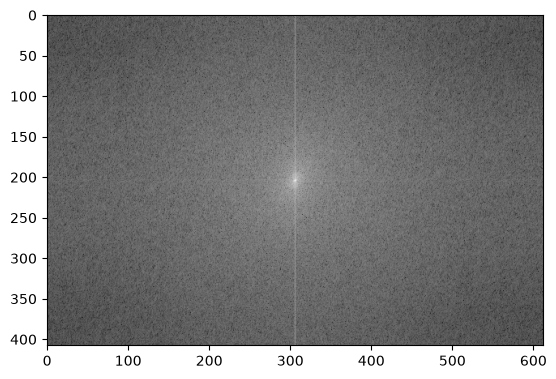

In [118]:
# [Lab 4 | cell 15] Display centred magnitude spectrum
plt.imshow(magnitude,cmap='gray')
plt.show()

### 4.3 Discrete Cosine Transform (DCT)
Convert to float32 then apply `cv2.dct`. Log display shows the coefficients better.

In [119]:
# [Lab 4 | cell 16] Convert image to float32
# Convert image to float
image_float = np.float32(image2)
image_float

array([[180., 181., 181., ..., 117., 117., 117.],
       [180., 180., 181., ..., 118., 118., 118.],
       [179., 180., 180., ..., 120., 120., 120.],
       ...,
       [ 32.,  34.,  32., ...,  80.,  10.,  39.],
       [ 36.,  21.,  14., ...,  62.,   0.,  35.],
       [ 46.,  16.,   4., ...,  70.,  15.,  72.]],
      shape=(408, 612), dtype=float32)

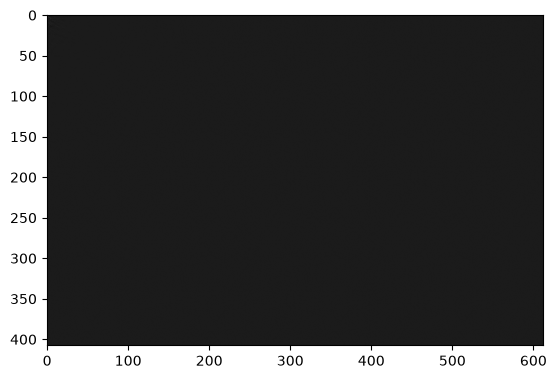

In [120]:
# [Lab 4 | cell 17] Apply DCT and display
#converting to dct

dct_image = cv2.dct(image_float)
plt.imshow(dct_image, cmap='gray')
plt.show()

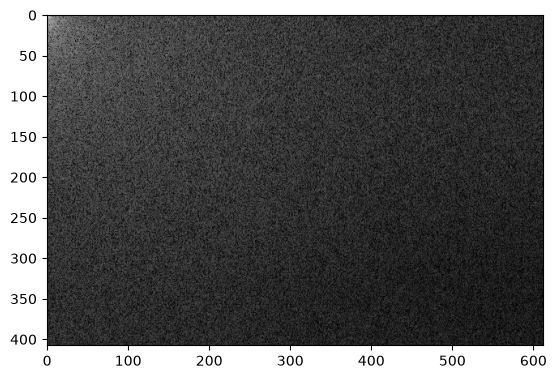

In [121]:
# [Lab 4 | cell 18] Display DCT with log scaling
plt.imshow(np.log(np.abs(dct_image) + 1), cmap='gray')
plt.show()

---
# Lab 5 — Spatial Domain Filters (Smoothing and Sharpening)

### 5.1 Read image, RGB and gray


In [122]:
# [Lab 5 | cell 1] Imports
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [123]:
# [Lab 5 | cell 2] Read image
#image = cv2.imread(IMG_NATURAL)
image = cv2.imread(IMG_SMALL)
image

array([[[132,  83, 145],
        [132,  83, 145],
        [132,  83, 145],
        ...,
        [186, 137, 181],
        [186, 137, 181],
        [186, 137, 181]],

       [[132,  83, 145],
        [132,  83, 145],
        [132,  83, 145],
        ...,
        [186, 137, 181],
        [186, 137, 181],
        [186, 137, 181]],

       [[132,  83, 145],
        [132,  83, 145],
        [132,  83, 145],
        ...,
        [186, 137, 181],
        [186, 137, 181],
        [186, 137, 181]],

       ...,

       [[195, 134, 184],
        [193, 135, 183],
        [195, 134, 184],
        ...,
        [199, 125, 149],
        [199, 125, 149],
        [199, 125, 149]],

       [[193, 135, 183],
        [194, 136, 184],
        [194, 136, 184],
        ...,
        [199, 125, 149],
        [199, 125, 149],
        [199, 125, 149]],

       [[194, 139, 184],
        [193, 138, 183],
        [193, 138, 183],
        ...,
        [199, 125, 149],
        [199, 125, 149],
        [199, 125, 149]]

In [124]:
# [Lab 5 | cell 3] Shape
image.shape

(1785, 3173, 3)

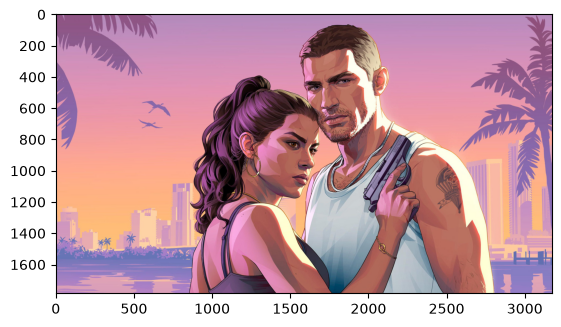

In [125]:
# [Lab 5 | cell 4] BGR -> RGB and display
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image_rgb)
plt.show()

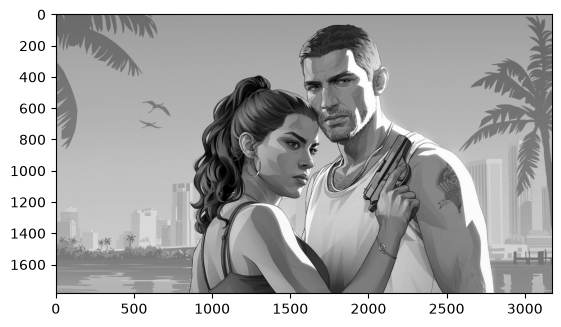

In [126]:
# [Lab 5 | cell 5] Convert to gray and display
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap='gray')
plt.show()

### 5.2 Correlation vs Convolution
Correlation uses the kernel as is; convolution flips the kernel first.

In [127]:
# [Lab 5 | cell 6] Define 3x3 kernel (Sobel-like)
# Define a 3x3 kernel
kernel = np.array([
    [1, 2, 1],
    [0, 0, 0],
    [-1, -2, -1]
])
kernel

array([[ 1,  2,  1],
       [ 0,  0,  0],
       [-1, -2, -1]])

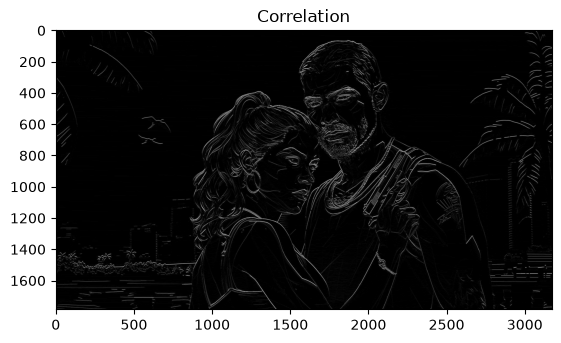

In [128]:
# [Lab 5 | cell 7] Correlation using filter2D
# ---------------------------------------------------
# CORRELATION
# ---------------------------------------------------
# In correlation, the kernel is NOT flipped.

correlation = cv2.filter2D(image_gray, -1, kernel)

plt.imshow(correlation, cmap='gray')
plt.title("Correlation")
plt.show()

In [129]:
# [Lab 5 | cell 8] Flip the kernel
flipped_kernel = np.flip(kernel)
flipped_kernel

array([[-1, -2, -1],
       [ 0,  0,  0],
       [ 1,  2,  1]])

In [130]:
# [Lab 5 | cell 9] Convolution = filter2D with flipped kernel
convolution = cv2.filter2D(
    image_gray,
    -1,
    flipped_kernel
)

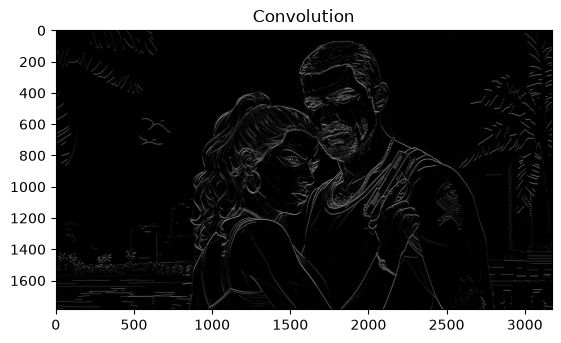

In [131]:
# [Lab 5 | cell 10] Display convolution result
plt.imshow(convolution, cmap='gray')
plt.title("Convolution")
plt.show()

### 5.3 Smoothing filters — Mean (Average) filter
Averages neighbouring pixels to blur / remove noise. Cells 17-21 show the (impractical) image-sized kernel for comparison.

In [132]:
# [Lab 5 | cell 12] Create 3x3 array of ones
# Smoothing Filters
# ---------------------------------------------------
#  MEAN / AVERAGE FILTER
# ---------------------------------------------------

ones_array = np.ones((3, 3))
ones_array

array([[1., 1., 1.],
       [1., 1., 1.],
       [1., 1., 1.]])

In [133]:
# [Lab 5 | cell 13] Mean kernel (ones / 9)
mean_kernel = ones_array/9
mean_kernel

array([[0.11111111, 0.11111111, 0.11111111],
       [0.11111111, 0.11111111, 0.11111111],
       [0.11111111, 0.11111111, 0.11111111]])

In [134]:
# [Lab 5 | cell 14] Apply mean filter
mean_filtered = cv2.filter2D(image_gray, -1, mean_kernel)

In [135]:
# [Lab 5 | cell 15] Print filtered values
mean_filtered

array([[107, 107, 107, ..., 156, 156, 156],
       [107, 107, 107, ..., 156, 156, 156],
       [107, 107, 107, ..., 156, 156, 156],
       ...,
       [158, 157, 158, ..., 141, 141, 141],
       [157, 157, 157, ..., 141, 141, 141],
       [157, 157, 157, ..., 141, 141, 141]],
      shape=(1785, 3173), dtype=uint8)

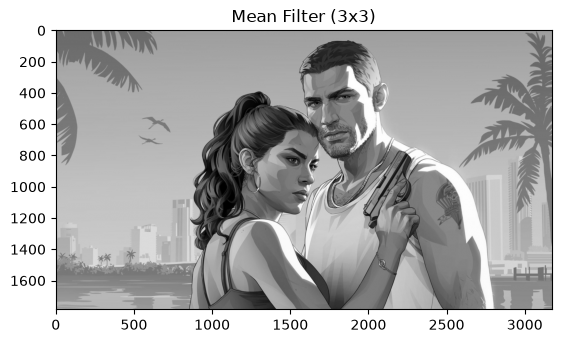

In [136]:
# [Lab 5 | cell 16] Display mean filtered image
plt.imshow(mean_filtered, cmap='gray')
plt.title("Mean Filter (3x3)")
plt.show()

In [137]:
# [Lab 5 | cell 17] Gray shape
image_gray.shape

(1785, 3173)

In [138]:
# [Lab 5 | cell 18] Mean kernel of image size
#creating the mean filter of an image size
mean_filter_image_size = np.ones(image_gray.shape)/9
mean_filter_image_size

array([[0.11111111, 0.11111111, 0.11111111, ..., 0.11111111, 0.11111111,
        0.11111111],
       [0.11111111, 0.11111111, 0.11111111, ..., 0.11111111, 0.11111111,
        0.11111111],
       [0.11111111, 0.11111111, 0.11111111, ..., 0.11111111, 0.11111111,
        0.11111111],
       ...,
       [0.11111111, 0.11111111, 0.11111111, ..., 0.11111111, 0.11111111,
        0.11111111],
       [0.11111111, 0.11111111, 0.11111111, ..., 0.11111111, 0.11111111,
        0.11111111],
       [0.11111111, 0.11111111, 0.11111111, ..., 0.11111111, 0.11111111,
        0.11111111]], shape=(1785, 3173))

In [139]:
# [Lab 5 | cell 19] Apply image-size mean filter
mean_filtered = cv2.filter2D(image_gray, -1, mean_filter_image_size)

In [140]:
# [Lab 5 | cell 20] Print values
mean_filtered

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]],
      shape=(1785, 3173), dtype=uint8)

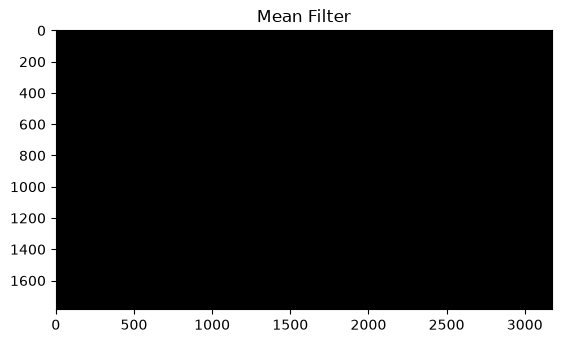

In [141]:
# [Lab 5 | cell 21] Display image-size mean filter result
plt.imshow(mean_filtered, cmap='gray')
plt.title("Mean Filter")
plt.show()

### 5.4 Smoothing filters — Gaussian (Weighted average) filter
Gives centre pixels more weight than the corners.

In [142]:
# [Lab 5 | cell 22] Define Gaussian kernel
# ---------------------------------------------------
#  Gaussian / Weighted AVERAGE FILTER
# ---------------------------------------------------
gaussian_kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
])
gaussian_kernel

array([[1, 2, 1],
       [2, 4, 2],
       [1, 2, 1]])

In [143]:
# [Lab 5 | cell 23] Normalise kernel (/16)
gaussian_kernel = gaussian_kernel/16
gaussian_kernel

array([[0.0625, 0.125 , 0.0625],
       [0.125 , 0.25  , 0.125 ],
       [0.0625, 0.125 , 0.0625]])

In [144]:
# [Lab 5 | cell 24] Apply Gaussian filter
gaussian_filtered = cv2.filter2D(image_gray, -1, gaussian_kernel)
gaussian_filtered

array([[107, 107, 107, ..., 156, 156, 156],
       [107, 107, 107, ..., 156, 156, 156],
       [107, 107, 107, ..., 156, 156, 156],
       ...,
       [157, 157, 157, ..., 141, 141, 141],
       [157, 157, 157, ..., 141, 141, 141],
       [158, 158, 158, ..., 141, 141, 141]],
      shape=(1785, 3173), dtype=uint8)

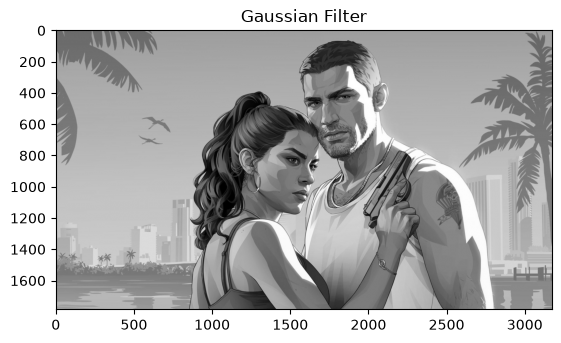

In [145]:
# [Lab 5 | cell 25] Display Gaussian filtered image
plt.imshow(gaussian_filtered, cmap='gray')
plt.title("Gaussian Filter")
plt.show()

### 5.5 Sharpening — First-order derivative filters
Roberts, Prewitt and Sobel detect edges using the first derivative (gradient).

In [146]:
# [Lab 5 | cell 27] Roberts kernel (2x2)
#Sharpening Filters
# ---------------------------------------------------
#  Robert Mask
# ---------------------------------------------------
robert_kernel = np.array([
    [-1,0],
    [0,1]
])
robert_kernel

array([[-1,  0],
       [ 0,  1]])

In [147]:
# [Lab 5 | cell 28] Apply Roberts filter
robert_filtered = cv2.filter2D(image_gray, -1, robert_kernel)
robert_filtered

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 1, 1, ..., 0, 0, 0],
       [2, 2, 1, ..., 0, 0, 0]], shape=(1785, 3173), dtype=uint8)

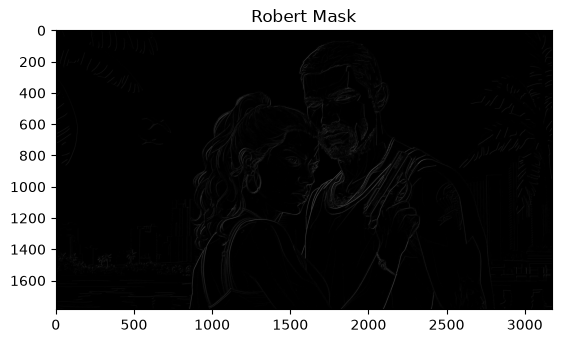

In [148]:
# [Lab 5 | cell 29] Display Roberts result
plt.imshow(robert_filtered, cmap='gray')
plt.title("Robert Mask")
plt.show()

In [149]:
# [Lab 5 | cell 30] Prewitt kernel
# ---------------------------------------------------
#  Prewitt Mask
# ---------------------------------------------------
prewitt_kernel = np.array([
    [-1,-1,-1],
    [0,0,0],
    [1,1,1]
])
prewitt_kernel

array([[-1, -1, -1],
       [ 0,  0,  0],
       [ 1,  1,  1]])

In [150]:
# [Lab 5 | cell 31] Apply Prewitt filter
prewitt_filtered = cv2.filter2D(image_gray, -1, prewitt_kernel)
prewitt_filtered

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 3, 3, 3],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [7, 7, 5, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(1785, 3173), dtype=uint8)

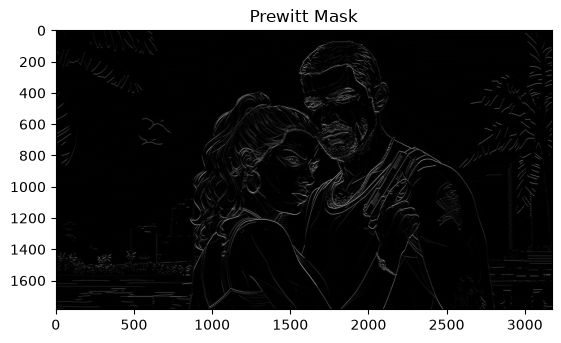

In [151]:
# [Lab 5 | cell 32] Display Prewitt result
plt.imshow(prewitt_filtered, cmap='gray')
plt.title("Prewitt Mask")
plt.show()

In [152]:
# [Lab 5 | cell 33] Sobel kernel
# ---------------------------------------------------
#  Sobel Mask
# ---------------------------------------------------
sobel_kernel = np.array([
    [-1,-2,-1],
    [0,0,0],
    [1,2,1]
])
sobel_kernel

array([[-1, -2, -1],
       [ 0,  0,  0],
       [ 1,  2,  1]])

In [153]:
# [Lab 5 | cell 34] Apply Sobel filter
sobel_filtered = cv2.filter2D(image_gray, -1, sobel_kernel)
sobel_filtered

array([[ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  4,  4,  4],
       ...,
       [ 0,  0,  0, ...,  0,  0,  0],
       [10,  9,  7, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0]], shape=(1785, 3173), dtype=uint8)

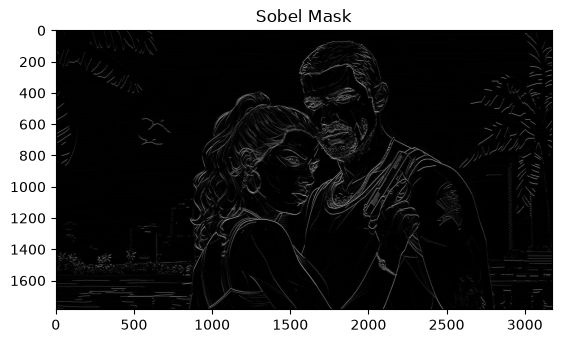

In [154]:
# [Lab 5 | cell 35] Display Sobel result
plt.imshow(sobel_filtered, cmap='gray')
plt.title("Sobel Mask")
plt.show()

### 5.6 Sharpening — Second-order derivative filters
Laplacian variants detect edges using the second derivative.

In [155]:
# [Lab 5 | cell 37] Laplacian kernel (4-neighbour)
# ---------------------------------------------------
#  Laplacian Mask
# ---------------------------------------------------
laplacian_kernel = np.array([
    [0,1,0],
    [1,-4,1],
    [0,1,0]
])
laplacian_kernel

array([[ 0,  1,  0],
       [ 1, -4,  1],
       [ 0,  1,  0]])

In [156]:
# [Lab 5 | cell 38] Apply Laplacian
laplacian_filtered = cv2.filter2D(image_gray, -1, laplacian_kernel)
laplacian_filtered

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 1, 1, 1],
       ...,
       [4, 5, 4, ..., 0, 0, 0],
       [5, 0, 1, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(1785, 3173), dtype=uint8)

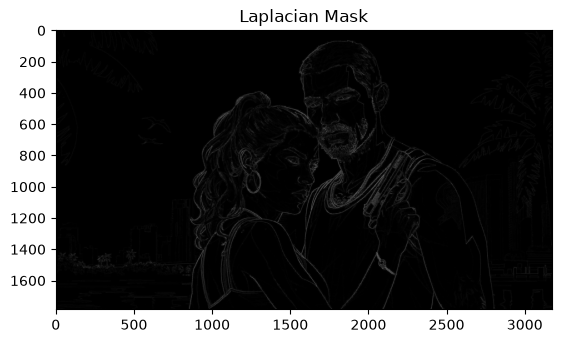

In [157]:
# [Lab 5 | cell 39] Display Laplacian result
plt.imshow(laplacian_filtered, cmap='gray')
plt.title("Laplacian Mask")
plt.show()

In [158]:
# [Lab 5 | cell 40] Laplacian kernel with diagonals
# ---------------------------------------------------
#  Second Laplacian Mask Considering Diagonals
# ---------------------------------------------------
laplacian_kernel2 = np.array([
    [1,1,1],
    [1,-8,1],
    [1,1,1]
])
laplacian_kernel2

array([[ 1,  1,  1],
       [ 1, -8,  1],
       [ 1,  1,  1]])

In [159]:
# [Lab 5 | cell 41] Apply Laplacian (diagonals)
laplacian_filtered2 = cv2.filter2D(image_gray, -1, laplacian_kernel2)
laplacian_filtered2

array([[ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  3,  3,  3],
       ...,
       [14, 13, 14, ...,  0,  0,  0],
       [ 9,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0]], shape=(1785, 3173), dtype=uint8)

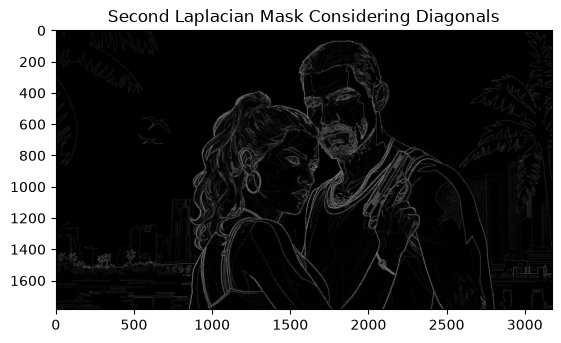

In [160]:
# [Lab 5 | cell 42] Display result
plt.imshow(laplacian_filtered2, cmap='gray')
plt.title("Second Laplacian Mask Considering Diagonals")
plt.show()

In [161]:
# [Lab 5 | cell 43] Enhanced Laplacian kernel (centre -9)
# ---------------------------------------------------
#  Enhanced Laplacian Mask
# ---------------------------------------------------
enhanced_laplacian_kernel = np.array([
    [1,1,1],
    [1,-9,1],
    [1,1,1]
])
enhanced_laplacian_kernel

array([[ 1,  1,  1],
       [ 1, -9,  1],
       [ 1,  1,  1]])

In [162]:
# [Lab 5 | cell 44] Apply Enhanced Laplacian
enhanced_laplacian_filtered = cv2.filter2D(image_gray, -1, enhanced_laplacian_kernel)
enhanced_laplacian_filtered

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(1785, 3173), dtype=uint8)

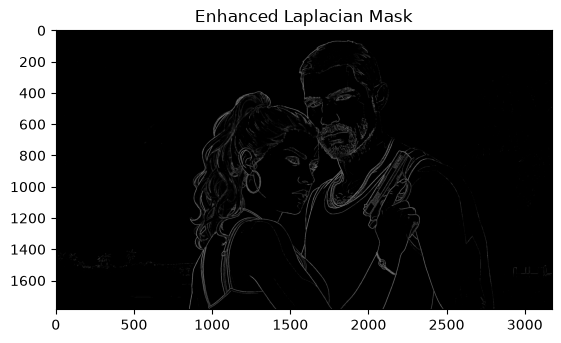

In [163]:
# [Lab 5 | cell 45] Display result
plt.imshow(enhanced_laplacian_filtered, cmap='gray')
plt.title("Enhanced Laplacian Mask")
plt.show()

### 5.7 Unsharp Masking and High-boost filtering
`A` controls the boost: A=1 is unsharp masking, A>1 is high-boost.

In [164]:
# [Lab 5 | cell 46] Define high-boost kernel with A = 1.7
# ---------------------------------------------------
#  Unsharp Masking and Highboost filter
# ---------------------------------------------------
A = 1.7
highboost_kernel = np.array([
    [0,1,0],
    [1,A+4,1],
    [0,1,0]
])
highboost_kernel

array([[0. , 1. , 0. ],
       [1. , 5.7, 1. ],
       [0. , 1. , 0. ]])

In [165]:
# [Lab 5 | cell 47] Apply high-boost filter
highboost_filtered = cv2.filter2D(image_gray, -1, highboost_kernel)
highboost_filtered

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]],
      shape=(1785, 3173), dtype=uint8)

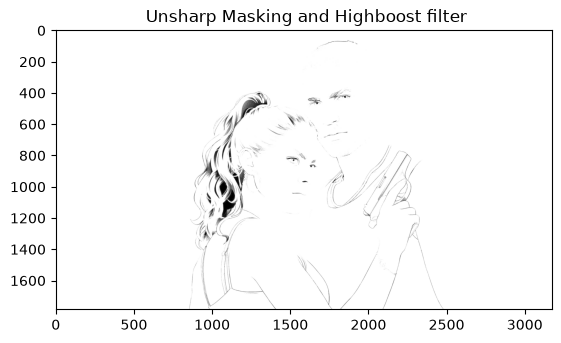

In [166]:
# [Lab 5 | cell 48] Display high-boost result
plt.imshow(highboost_filtered, cmap='gray')
plt.title(" Unsharp Masking and Highboost filter")
plt.show()

---
# Lab 6 — Frequency Domain Filters *(added by me — was missing from your zip)*
Steps: FFT → shift → multiply by a filter mask (low-pass keeps low frequencies = blur; high-pass keeps high frequencies = edges) → inverse shift → inverse FFT.

### 6.1 Read image, FFT and build distance grid
Creates the FFT of the image and `D` = distance of every frequency point from the centre. `D0` is the cut-off radius.

In [167]:
# [Lab 6 | NEW] Read gray image, take FFT, compute distance-from-centre grid D
image_gray = cv2.imread(IMG_SMALL, 0)
rows, cols = image_gray.shape
crow, ccol = rows // 2, cols // 2

fshift = np.fft.fftshift(np.fft.fft2(image_gray))        # centred spectrum

u = np.arange(rows) - crow
v = np.arange(cols) - ccol
V, U = np.meshgrid(v, u)
D = np.sqrt(U**2 + V**2)                                  # distance from centre

D0 = 30        # cut-off frequency (radius). Smaller = more blur for LPF
n  = 2         # Butterworth order

### 6.2 Helper function to apply any frequency mask
Multiplies the spectrum by the mask and goes back to the spatial domain.

In [168]:
# [Lab 6 | NEW] Helper: apply a frequency-domain mask and return the filtered image
def apply_freq_filter(fshift, mask):
    filtered = fshift * mask
    img_back = np.fft.ifft2(np.fft.ifftshift(filtered))
    return np.abs(img_back)

def show_result(mask, result, title):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1); plt.imshow(image_gray, cmap='gray'); plt.title("Original"); plt.axis('off')
    plt.subplot(1, 3, 2); plt.imshow(mask, cmap='gray');       plt.title(title + " mask"); plt.axis('off')
    plt.subplot(1, 3, 3); plt.imshow(result, cmap='gray');     plt.title(title + " result"); plt.axis('off')
    plt.show()

### 6.3 Low-pass filters (smoothing / blurring)

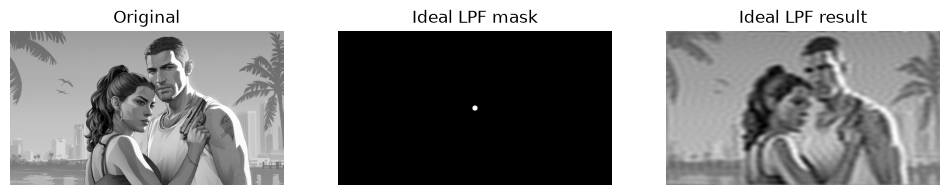

In [169]:
# [Lab 6 | NEW] Ideal Low-Pass Filter (sharp circular cut-off, causes ringing)
ilpf_mask = (D <= D0).astype(np.float32)
ilpf_result = apply_freq_filter(fshift, ilpf_mask)
show_result(ilpf_mask, ilpf_result, "Ideal LPF")

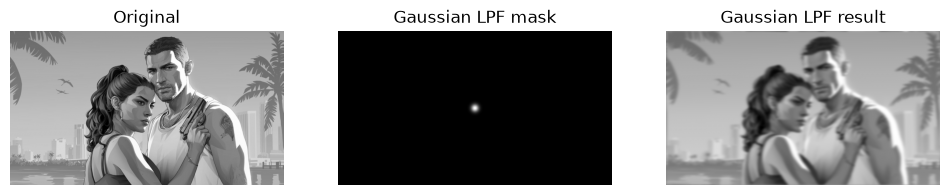

In [170]:
# [Lab 6 | NEW] Gaussian Low-Pass Filter (smooth cut-off, no ringing)
glpf_mask = np.exp(-(D**2) / (2 * D0**2))
glpf_result = apply_freq_filter(fshift, glpf_mask)
show_result(glpf_mask, glpf_result, "Gaussian LPF")

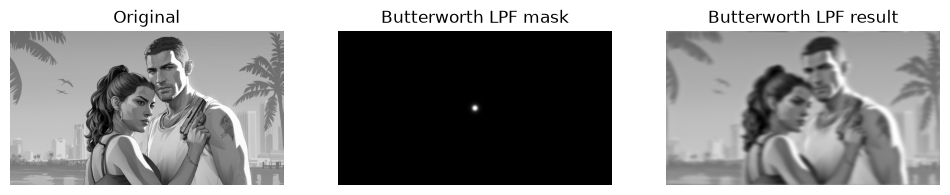

In [171]:
# [Lab 6 | NEW] Butterworth Low-Pass Filter (order n controls sharpness)
blpf_mask = 1 / (1 + (D / D0) ** (2 * n))
blpf_result = apply_freq_filter(fshift, blpf_mask)
show_result(blpf_mask, blpf_result, "Butterworth LPF")

### 6.4 High-pass filters (sharpening / edge enhancement)
High-pass mask = 1 − low-pass mask.

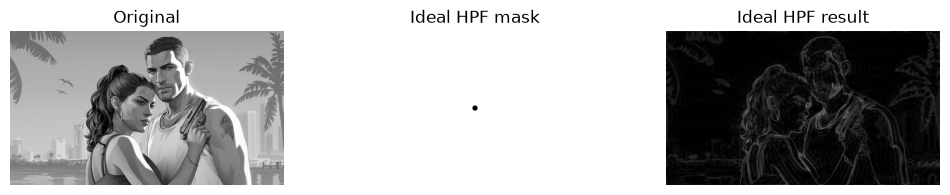

In [172]:
# [Lab 6 | NEW] Ideal High-Pass Filter
ihpf_mask = 1 - ilpf_mask
ihpf_result = apply_freq_filter(fshift, ihpf_mask)
show_result(ihpf_mask, ihpf_result, "Ideal HPF")

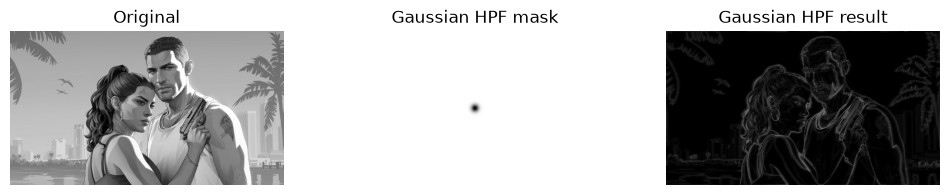

In [173]:
# [Lab 6 | NEW] Gaussian High-Pass Filter
ghpf_mask = 1 - glpf_mask
ghpf_result = apply_freq_filter(fshift, ghpf_mask)
show_result(ghpf_mask, ghpf_result, "Gaussian HPF")

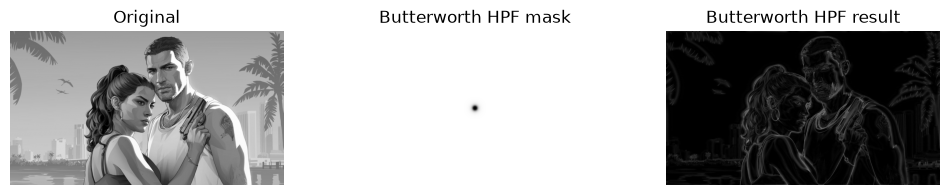

In [174]:
# [Lab 6 | NEW] Butterworth High-Pass Filter
bhpf_mask = 1 - blpf_mask
bhpf_result = apply_freq_filter(fshift, bhpf_mask)
show_result(bhpf_mask, bhpf_result, "Butterworth HPF")

---
# Lab 7 — Impulse (Salt & Pepper) Noise and Median Filter

### 7.1 Read image and convert to gray


In [175]:
# [Lab 7 | cell 0] Imports
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [176]:
# [Lab 7 | cell 1] Read image
# --------------------------------------------------
# 1. Read the original image
# --------------------------------------------------
image = cv2.imread(IMG_SMALL)

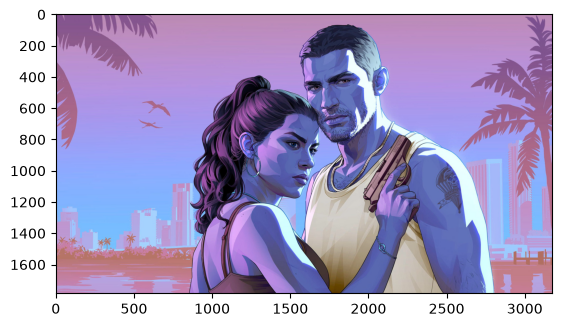

In [177]:
# [Lab 7 | cell 2] Display image (BGR shown directly, colours look off)
plt.imshow(image)
plt.show()

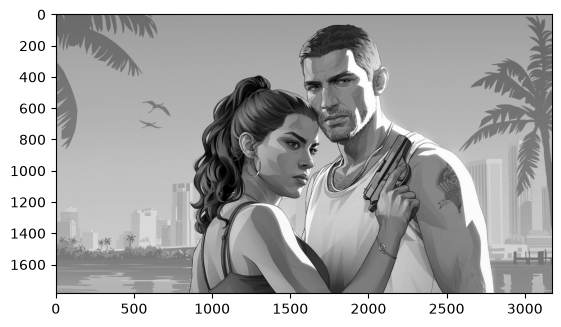

In [178]:
# [Lab 7 | cell 3] Convert to gray and display
image_gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap='gray')
plt.show()

### 7.2 Set up noise parameters
`noise_density` = fraction of pixels to corrupt. Cells 6-8 just explain how image size relates to pixel count.

In [179]:
# [Lab 7 | cell 4] Copy gray image for noise
# 2. Add impulse (salt-and-pepper) noise
noisy_image = image_gray.copy()

In [180]:
# [Lab 7 | cell 5] Noise density = 5%
# Noise density: fraction of pixels affected
noise_density = 0.05

In [181]:
# [Lab 7 | cell 6] Image shape
image_gray.shape

(1785, 3173)

In [182]:
# [Lab 7 | cell 7] Manual calculation rows*cols
523*382

199786

In [183]:
# [Lab 7 | cell 8] Total pixels using .size
image_gray.size

5663805

In [184]:
# [Lab 7 | cell 9] Number of pixels to corrupt
# Number of pixels to corrupt
num_pixels = int(noise_density * image_gray.size)
num_pixels

283190

In [185]:
# [Lab 7 | cell 10] Rows and columns
# Randomly select pixel coordinates
rows, cols = image_gray.shape
print("Row =",rows,"Cols=",cols)

Row = 1785 Cols= 3173


### 7.3 Add Salt noise (white pixels)
Randomly picks pixel positions and sets them to 255.

In [186]:
# [Lab 7 | cell 11] Add salt noise
# Add salt noise (white pixels)
num_salt = num_pixels // 2
print("Num Salt =",num_salt)
salt_rows = np.random.randint(0, rows, num_salt)
salt_cols = np.random.randint(0, cols, num_salt)
noisy_image[salt_rows, salt_cols] = 255

Num Salt = 141595


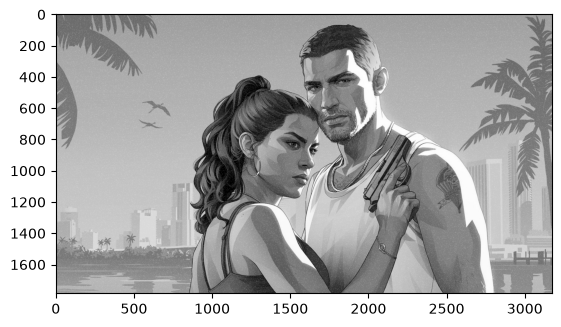

In [187]:
# [Lab 7 | cell 12] Display image with salt noise
plt.imshow(noisy_image, cmap='gray')
plt.show()

### 7.4 Small NumPy demo of random indexing (learning cell)
Shows how fancy indexing `a[rows, cols] = 255` works on a tiny array. Not needed for the actual task.

In [188]:
# [Lab 7 | cell 13] Create 4x5 demo array
a = np.arange(1,21).reshape(4,5)
a

array([[ 1,  2,  3,  4,  5],
       [ 6,  7,  8,  9, 10],
       [11, 12, 13, 14, 15],
       [16, 17, 18, 19, 20]])

In [189]:
# [Lab 7 | cell 14] Random rows/cols and set to 255
s_r = np.random.randint(0, 4, 5)
print("salt rows=",s_r)
s_c = np.random.randint(0, 5, 5)
print("salt_cols=",s_c)
a[s_r, s_c] = 255

salt rows= [1 3 0 3 0]
salt_cols= [2 0 4 0 1]


In [190]:
# [Lab 7 | cell 15] Show the array
a

array([[  1, 255,   3,   4, 255],
       [  6,   7, 255,   9,  10],
       [ 11,  12,  13,  14,  15],
       [255,  17,  18,  19,  20]])

### 7.5 Add Pepper noise (black pixels)
Randomly picks pixel positions and sets them to 0.

In [191]:
# [Lab 7 | cell 16] Add pepper noise
# Add pepper noise (black pixels)
num_pepper = num_pixels - num_salt
pepper_rows = np.random.randint(0, rows, num_pepper)
pepper_cols = np.random.randint(0, cols, num_pepper)
noisy_image[pepper_rows, pepper_cols] = 0

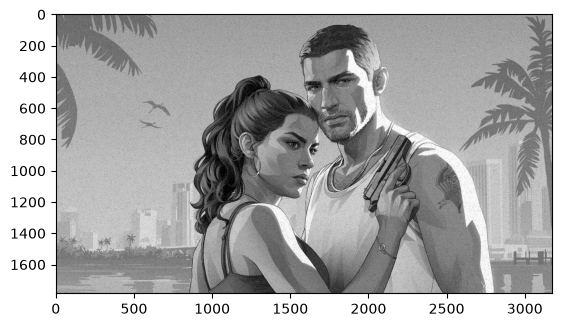

In [192]:
# [Lab 7 | cell 17] Display salt-and-pepper noisy image
plt.imshow(noisy_image, cmap='gray')
plt.show()

### 7.6 Remove noise using Median Filter
Median filter replaces each pixel with the median of its neighbourhood — best for salt-and-pepper noise.

In [193]:
# [Lab 7 | cell 18] Apply median filter (5x5)
# 3. Remove impulse noise using Median Filter
denoised_image = cv2.medianBlur(noisy_image, 5)

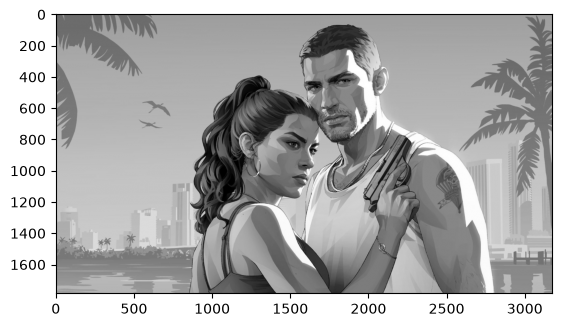

In [194]:
# [Lab 7 | cell 19] Display denoised image
plt.imshow(denoised_image, cmap='gray')
plt.show()

### 7.7 Compare histograms (original, noisy, denoised)


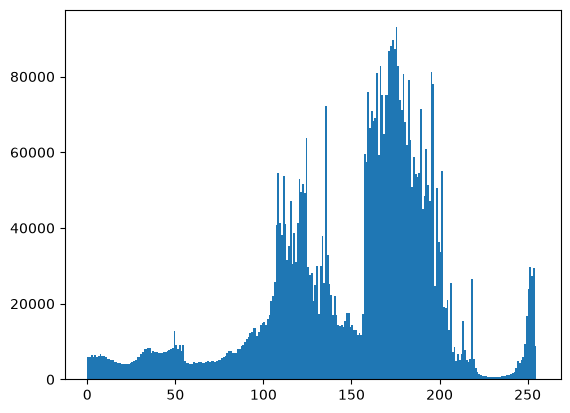

In [195]:
# [Lab 7 | cell 20] Histogram of original gray image
plt.hist(image_gray.ravel(), bins=256, range=[0, 256])
plt.show()

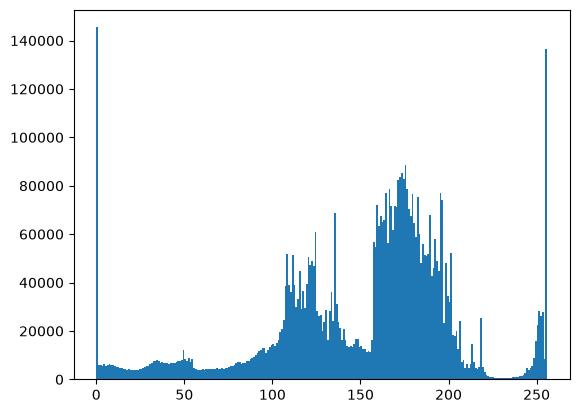

In [196]:
# [Lab 7 | cell 21] Histogram of noisy image
plt.hist(noisy_image.ravel(), bins=256, range=[0, 256])
plt.show()

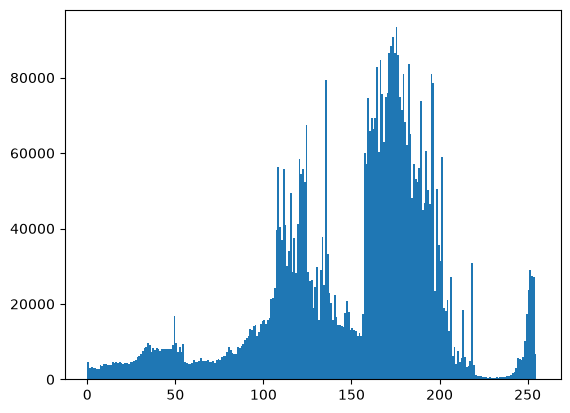

In [197]:
# [Lab 7 | cell 22] Histogram of denoised image
plt.hist(denoised_image.ravel(), bins=256, range=[0, 256])
plt.show()

---
# Lab 8 — Gaussian Noise and Gaussian Filter

### 8.1 Read image and convert to gray


In [198]:
# [Lab 8 | cell 0] Imports
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [199]:
# [Lab 8 | cell 1] Read image
# --------------------------------------------------
# 1. Read the original image
# --------------------------------------------------
image = cv2.imread(IMG_DOGKITTEN)

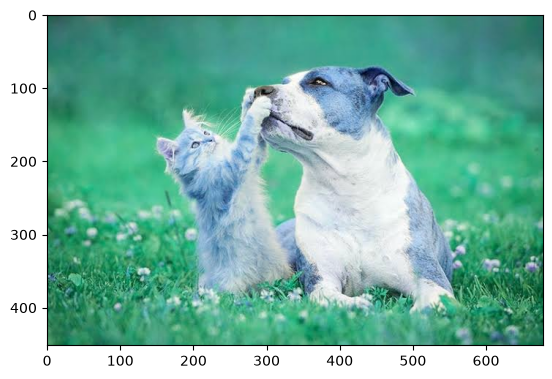

In [200]:
# [Lab 8 | cell 2] Display image (BGR shown directly)
plt.imshow(image)
plt.show()

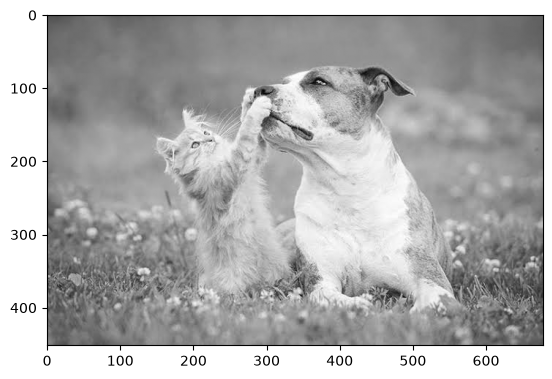

In [201]:
# [Lab 8 | cell 3] Convert to gray and display
image_gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap='gray')
plt.show()

In [202]:
# [Lab 8 | cell 4] Print gray pixel values
image_gray

array([[ 84,  84,  83, ...,  97,  97,  97],
       [ 84,  84,  84, ...,  97,  97,  97],
       [ 85,  85,  84, ...,  97,  97,  97],
       ...,
       [114, 122, 131, ...,  82,  82,  84],
       [111, 118, 125, ...,  82,  82,  84],
       [108, 113, 120, ...,  81,  81,  83]], shape=(452, 678), dtype=uint8)

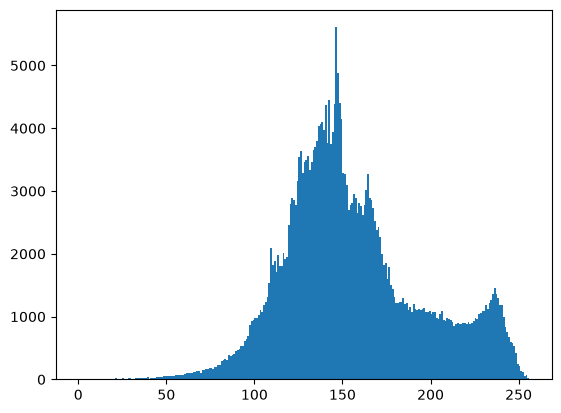

In [203]:
# [Lab 8 | cell 5] Histogram of gray image
plt.hist(image_gray.ravel(), bins=256, range=[0, 256])
plt.show()

### 8.2 Add Gaussian noise
Noise is drawn from a normal distribution with **mean = 0** and **std = 25**. Mean is 0 because noise can make pixels both brighter (+) and darker (−).

In [204]:
# [Lab 8 | cell 6] Random generator with fixed seed
# Use a fixed seed so the experiment is reproducible
rng = np.random.default_rng(42)
rng

Generator(PCG64) at 0x27EBDC84F20

In [205]:
# [Lab 8 | cell 8] Generate Gaussian noise (mean 0, std 25)
# 2. Add gaussina noise
noise = rng.normal(0, 25, image_gray.shape)
# mean = 0 and standard deviation = 25
noise

array([[  7.61792699, -25.99960266,  18.7612799 , ...,   8.73376556,
         59.56505707,  10.50471497],
       [  9.69257853,  -4.17319825,  20.41939668, ...,   8.8156801 ,
         47.82387019,  11.65444155],
       [ -9.40530259, -12.67763201, -10.25849933, ..., -12.33670523,
         16.48710536,  -9.92284603],
       ...,
       [  1.65776071,   1.22452738,   5.23979868, ...,   9.11801025,
        -42.27479679,  53.17560204],
       [ -7.41649051, -23.75630648,  31.5478832 , ...,  36.78129457,
         25.22207644,  16.12990741],
       [-17.33911265,   4.63939567,  36.0511993 , ..., -33.64302832,
         15.84217038,  34.52545982]], shape=(452, 678))

In [206]:
# [Lab 8 | cell 9] Add noise to gray image
noisy_image = image_gray + noise
noisy_image

array([[ 91.61792699,  58.00039734, 101.7612799 , ..., 105.73376556,
        156.56505707, 107.50471497],
       [ 93.69257853,  79.82680175, 104.41939668, ..., 105.8156801 ,
        144.82387019, 108.65444155],
       [ 75.59469741,  72.32236799,  73.74150067, ...,  84.66329477,
        113.48710536,  87.07715397],
       ...,
       [115.65776071, 123.22452738, 136.23979868, ...,  91.11801025,
         39.72520321, 137.17560204],
       [103.58350949,  94.24369352, 156.5478832 , ..., 118.78129457,
        107.22207644, 100.12990741],
       [ 90.66088735, 117.63939567, 156.0511993 , ...,  47.35697168,
         96.84217038, 117.52545982]], shape=(452, 678))

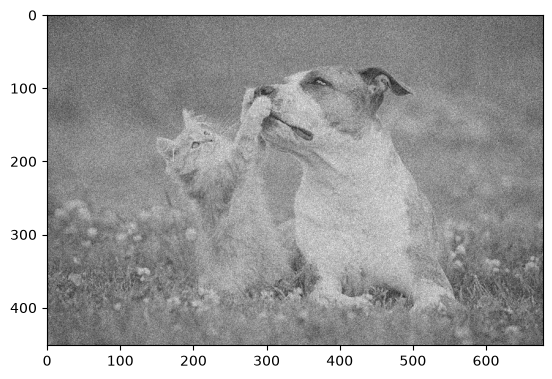

In [207]:
# [Lab 8 | cell 10] Display noisy image
plt.imshow(noisy_image, cmap='gray')
plt.show()

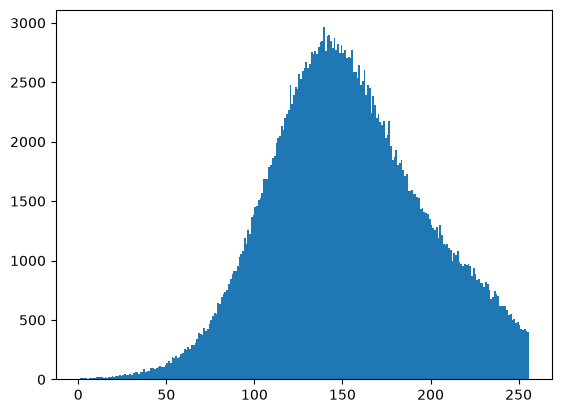

In [208]:
# [Lab 8 | cell 11] Histogram of noisy image
plt.hist(noisy_image.ravel(), bins=256, range=[0, 256])
plt.show()

### 8.3 Remove Gaussian noise using Gaussian filter
`GaussianBlur` with 5x5 kernel and sigma = 1.0.

In [209]:
# [Lab 8 | cell 13] Apply Gaussian filter
# 3. Remove gaussian noise using Gaussian Filter
denoised_image2 = cv2.GaussianBlur(noisy_image, (5,5), 1.0)

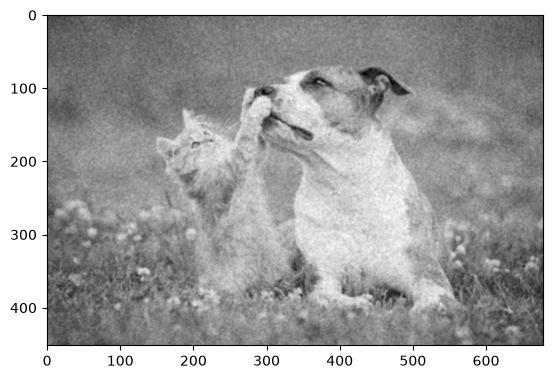

In [210]:
# [Lab 8 | cell 14] Display denoised image
plt.imshow(denoised_image2, cmap='gray')
plt.show()

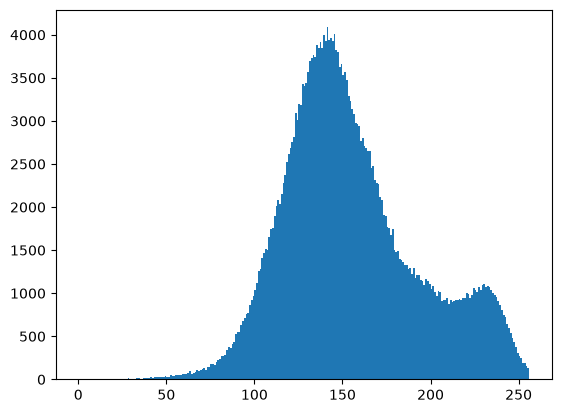

In [211]:
# [Lab 8 | cell 15] Histogram of denoised image
plt.hist(denoised_image2.ravel(), bins=256, range=[0, 256])
plt.show()

---
# Lab 9 — Image Thresholding (Global and Adaptive)

### 9.1 Read image and convert to gray


In [212]:
# [Lab 9 | cell 0] Imports
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [213]:
# [Lab 9 | cell 1] Read image
# --------------------------------------------------
# 1. Read the original image
# --------------------------------------------------
image = cv2.imread(IMG_DOGKITTEN)

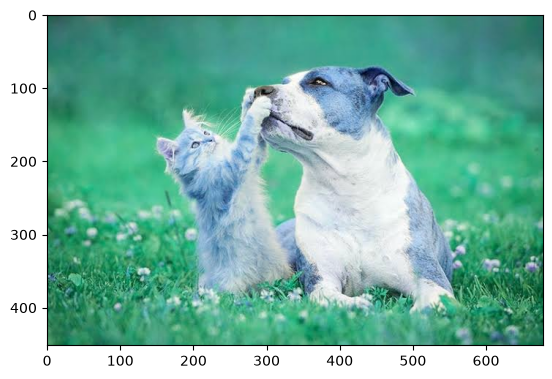

In [214]:
# [Lab 9 | cell 2] Display image (BGR shown directly)
plt.imshow(image)
plt.show()

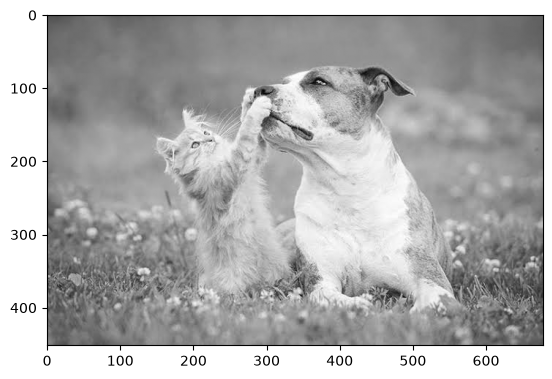

In [215]:
# [Lab 9 | cell 3] Convert to gray and display
image_gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap='gray')
plt.show()

### 9.2 Global thresholding
One threshold value (127) for the whole image: pixel > 127 → 255, else 0.

In [216]:
# [Lab 9 | cell 4] Apply global threshold
# Step 3: Apply Global Thresholding
# Single threshold value = 127
ret, global_thresh = cv2.threshold(
    image_gray, 127, 255, cv2.THRESH_BINARY
)

In [217]:
# [Lab 9 | cell 5] Print threshold value
print(ret)

127.0


In [218]:
# [Lab 9 | cell 6] Print thresholded matrix
print(global_thresh)

[[  0   0   0 ...   0   0   0]
 [  0   0   0 ...   0   0   0]
 [  0   0   0 ...   0   0   0]
 ...
 [  0   0 255 ...   0   0   0]
 [  0   0   0 ...   0   0   0]
 [  0   0   0 ...   0   0   0]]


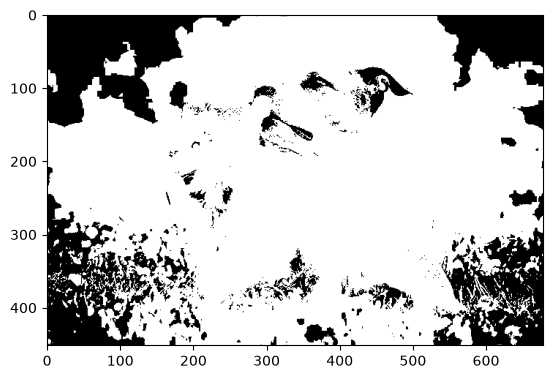

In [219]:
# [Lab 9 | cell 7] Display global threshold result
plt.imshow(global_thresh, cmap='gray')

### 9.3 Adaptive thresholding (Mean)
Threshold is calculated locally (11x11 neighbourhood mean minus constant 2) — works better with uneven lighting.

In [220]:
# [Lab 9 | cell 8] Apply adaptive mean threshold
adaptive_mean = cv2.adaptiveThreshold(
    image_gray, 255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    11, 2
)

In [221]:
# [Lab 9 | cell 9] Print result
adaptive_mean

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       ...,
       [  0, 255, 255, ...,   0,   0, 255],
       [  0,   0, 255, ...,   0,   0, 255],
       [  0,   0, 255, ...,   0,   0, 255]], shape=(452, 678), dtype=uint8)

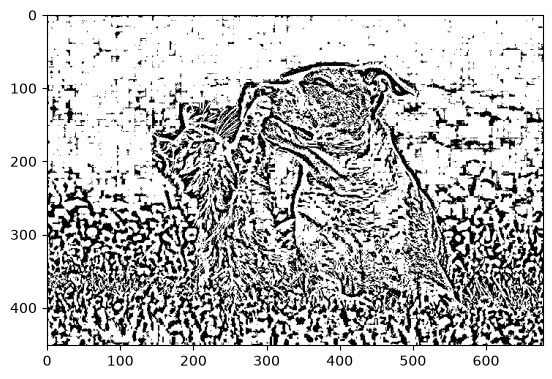

In [222]:
# [Lab 9 | cell 10] Display adaptive threshold result
plt.imshow(adaptive_mean,cmap='gray')